# Tugas Besar 2 IF3170 Inteligensi Artifisial

## Pendahuluan

Notebook ini membandingkan C4.5, SVM, regresi logistik, Naive Bayes, dan KNN untuk memprediksi pembatalan pemesanan hotel. Metrik utama untuk pemilihan kandidat adalah F1 makro. Jalankan sel dari atas ke bawah dengan kernel scikit-learn 1.7.1 agar partisi data dapat direproduksi.

## Daftar isi

1. [Impor, konfigurasi, dan data](#inisialisasi)
2. [Eksplorasi data (EDA)](#eda)
3. [Prapemrosesan dan definisi fitur](#preprocessing), termasuk [katalog kelompok fitur](#rekayasa-fitur)
4. [Pemodelan dan seleksi](#modeling): [C4.5](#c45), [SVM](#svm), [regresi logistik](#logreg), [Naive Bayes](#naive-bayes), [KNN](#knn), dan [uji lintas model](#pemilihan-fitur)
5. [Perbandingan baseline dan analisis biaya](#model-comparison)
6. [Pelatihan ulang dan ekspor](#final-fit)

## Impor dan konfigurasi <a id="inisialisasi"></a>

Jalankan notebook dari dalam repositori dengan kernel yang memakai `scikit-learn==1.7.1`; lihat petunjuk di `README.md`. Notebook menggunakan CPU, mencari data dari direktori repositori, dan menyimpan hasil di `output/`. Keluaran sel yang tersimpan berasal dari eksekusi sebelumnya; jalankan ulang untuk memperoleh hasil dengan versi 1.7.1.

In [ ]:
import os
import sys
import time
import random
import pickle
import warnings
from tempfile import TemporaryDirectory
from pathlib import Path
import pandas as pd
from sklearn import __version__ as sklearn_version
from threadpoolctl import threadpool_limits

if sklearn_version != '1.7.1':
    raise RuntimeError(
        f'Kernel memakai scikit-learn {sklearn_version}; notebook memerlukan tepat versi 1.7.1. '
        'Ikuti petunjuk di README.md, lalu pilih dan mulai ulang kernel yang sesuai.'
    )
# Locate the repository before importing its local SVM package.
_NOTEBOOK_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / 'src' / 'models' / 'svm').is_dir()
)
if str(_NOTEBOOK_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(_NOTEBOOK_ROOT / 'src'))
from models.svm import SVM
from models import LogisticRegressionClassifier
from models.booking_features import build_blocks, raw_groups
from models.booking_feature_search import (
    MODEL_NAMES,
    evaluate_feature_choices,
    feature_partitions,
    fit_feature_choices,
    select_feature_groups,
)

from sklearn.metrics import log_loss
from models.svm.visualization import plot_svm_boundary
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.animation as animation   
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder, LabelEncoder
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, mutual_info_classif, chi2
from sklearn.decomposition import PCA
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, StratifiedGroupKFold, cross_val_score, GridSearchCV
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    RocCurveDisplay, average_precision_score, precision_recall_curve
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree   # ID3/C4.5/CART 
from sklearn.linear_model import LogisticRegression         
from sklearn.svm import SVC                                 
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from scipy.stats import chi2_contingency
import copy
from models.c45 import C45DecisionTree
from models.c45.visualization import plot_tree as c45_plot_tree
from IPython.display import Video, display
from models import NaiveBayesClassifier, TreeAugmentedNaiveBayes
from models.naive_bayes.visualization import (
    feature_relations, plot_naive_bayes_graph, plot_tan_structure,
)
from models import KNNClassifier
from sklearn.preprocessing import FunctionTransformer
from sklearn.base import clone
from models import classification_cost, cost_sensitive_threshold, predict_cost_sensitive

In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ROOT = _NOTEBOOK_ROOT
DATA_DIR = ROOT / 'data'
OUTPUT_DIR = ROOT / 'output'

print(f'Root path: {ROOT}')
print(f'Data directory: {DATA_DIR}')
print(f'Output directory: {OUTPUT_DIR}')

## Memuat data

`train.csv` memuat target `is_canceled`; `test.csv` hanya memuat prediktor dan ID. ID digunakan untuk menyelaraskan submisi, bukan sebagai fitur model.

In [ ]:
train_file = DATA_DIR / "train.csv"
test_file = DATA_DIR / "test.csv"
train_df = pd.read_csv(train_file, dtype={'id': str})
test_df = pd.read_csv(test_file, dtype={'id': str})

## Eksplorasi data (EDA) <a id="eda"></a>

Bagian ini memeriksa distribusi target, kualitas data, dan hubungan antarfitur pada data latih. Temuannya membantu menjelaskan pilihan yang diuji pada tahap pemodelan.

Pemeriksaan dimulai dari struktur tabel dan distribusi target, lalu meninjau kualitas serta pola pada prediktor.

### 1. Gambaran Umum

In [ ]:
#Gambaran umum tentang dataset
print("Dataset Overview:")
train_df.info()
train_df.describe(include='all')

#### Insight
- Data training berisi 27.373 booking dengan 17 fitur, terdiri atas 14 fitur numerik dan 3 fitur kategorikal. Kolom id tidak dipakai karena hanya berisi kode unik.
- Skala fitur sangat berbeda. nightly_rate_idr bernilai jutaan, sedangkan fitur lain kebanyakan di bawah 20. Model seperti KNN, SVM, dan Logistic Regression perlu scaling terlebih dahulu.

### 2. Distribusi Target

In [ ]:
target_counts = train_df['is_canceled'].value_counts()
print("Target Variable Distribution:")
print(target_counts)

#### Insight
- Sekitar 67% booking tidak dibatalkan dan 33% dibatalkan.
- Model yang selalu menebak "tidak batal" sudah mendapat accuracy 67%, jadi evaluasi perlu memakai metrik lain seperti F1 dan ROC AUC.

### 3. Missing Values

In [ ]:
# Missing values
missing_val_per_col = {col: train_df[col].isnull().sum() for col in train_df.columns}
for col, missing_count in missing_val_per_col.items():
    if missing_count > 0:
        print(f"Column '{col}' has {missing_count} missing values.")

#### Insight
- Delapan kolom memiliki nilai kosong, paling banyak pada num_children (11%). Kolom lain kosong kurang dari 10%.
- Sekitar 39% baris memiliki minimal satu nilai kosong, sehingga menghapus baris akan membuang terlalu banyak data. Nilai kosong lebih baik diisi dengan median untuk fitur numerik dan modus untuk fitur kategorikal.

### 4. Data duplikat dan tidak valid

In [ ]:
duplicate_rows = train_df[train_df.duplicated()]
print(f"Number of duplicate rows in the training dataset: {len(duplicate_rows)}")

In [ ]:
unused_features = ['id', 'is_canceled']

#### Insight
- Tidak ada baris duplikat. Namun, jika id diabaikan, ada 64 baris yang isinya sama persis dengan baris lain. Baris seperti ini perlu dijaga agar tidak masuk ke training dan validation sekaligus.
- Tarif 0 pada 413 booking bukan kesalahan data karena sebagian besar berasal dari kanal Complimentary.

### 5. Fitur numerik

In [ ]:
#Fitur numerik minus target dan id
numeric_features = train_df.select_dtypes(include=['int64', 'float64']).columns.tolist()
numeric_features = [col for col in numeric_features if col not in unused_features]
print(f"Numeric features: {numeric_features}")


In [ ]:
# Statistik deskriptif untuk fitur numerik dan histogram distribusi
for feature in numeric_features:
    print(f"\nFeature: {feature}")
    print(train_df[feature].describe())
    plt.figure(figsize=(8, 4))
    sns.histplot(train_df[feature], kde=True, bins=30)
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.show()

#### Insight
- Beberapa fitur hampir selalu bernilai 0, yaitu needs_parking, is_returning_guest, prior_cancellations, dan prior_completed_bookings. Informasinya hanya ada pada sebagian kecil booking.
- days_before_arrival miring ke kanan. Sebagian besar booking dibuat paling lama sekitar 4 bulan sebelum kedatangan, tetapi ada yang sampai 448 hari.

In [ ]:
# Outlier 
for feature in numeric_features:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=train_df[feature])
    plt.title(f'Boxplot of {feature}')
    plt.xlabel(feature)
    plt.show()

#### Insight
- Outlier terbanyak ada pada nightly_rate_idr dan days_before_arrival. Nilainya masih wajar sehingga tidak dihapus.
- Pada fitur diskret seperti num_adults dan num_children, banyak nilai ditandai outlier hanya karena datanya didominasi satu nilai, bukan karena salah.

### 6. Fitur kategorikal

In [ ]:
categorical_features = train_df.select_dtypes(include=['object']).columns.tolist()
categorical_features = [col for col in categorical_features if col not in unused_features]
print(f"Categorical features: {categorical_features}")

In [ ]:
#Hitung jumlah nilai dan cancel rate per kategori untuk fitur kategorikal
for feature in categorical_features:
    value_counts = train_df[feature].value_counts()
    cancel_rate = train_df.groupby(feature)['is_canceled'].mean()
    print(f"\nFeature: {feature}")
    print("Value Counts:")
    print(value_counts)
    print("Cancel Rate:")
    print(cancel_rate)

In [ ]:
for feature in categorical_features:
    rare_categories = train_df[feature].value_counts()[train_df[feature].value_counts() < 10].index.tolist()
    if rare_categories:
        print(f"\nFeature: {feature} has rare categories: {rare_categories}")


In [ ]:
for feature in categorical_features:
    train_categories = set(train_df[feature].unique())
    test_categories = set(test_df[feature].unique())
    unseen_categories = test_categories - train_categories
    if unseen_categories:
        print(f"\nFeature: {feature} has unseen categories in test data: {unseen_categories}")

#### Insight
- booking_channel paling membedakan pembatalan. Online Travel Agent paling sering batal (36%), Corporate jarang (12%), dan Complimentary tidak pernah batal.
- Pada meal_package, Half Board paling sering batal (46%). Pada room_category, Type A paling sering batal (43%).
- Full Board dan Type E muncul kurang dari 10 kali, jadi cancel rate-nya belum bisa dipercaya.

### 7. Hubungan antarfitur

In [ ]:
#Heatmap korelasi untuk fitur numerik dan target
numeric_features_with_target = numeric_features + ['is_canceled']
plt.figure(figsize=(10, 8))
sns.heatmap(train_df[numeric_features_with_target].corr(), annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

#### Insight
- days_before_arrival paling berhubungan dengan pembatalan (0,44). Makin jauh hari booking dibuat, makin besar peluangnya dibatalkan.
- special_requests berhubungan terbalik (−0,26). Tamu yang punya permintaan khusus lebih jarang membatalkan.

In [ ]:
# Hubungan antara fitur kategorikal dan target
for feature in categorical_features:
    plt.figure(figsize=(8, 4))
    sns.barplot(x=feature, y='is_canceled', data=train_df)
    plt.title(f'Cancel Rate by {feature}')
    plt.xlabel(feature)
    plt.ylabel('Cancel Rate')
    plt.xticks(rotation=45)
    plt.show()

#### Insight
- Grafik menunjukkan hal yang sama dengan tabel sebelumnya. Perbedaan paling besar ada pada booking_channel, sedangkan perbedaan antar-room_category lebih kecil.

In [ ]:
#Hubungan pake chi-square test untuk fitur kategorikal dan target
categorical_features_with_target = categorical_features + ['is_canceled']
for feature in categorical_features:
    contingency_table = pd.crosstab(train_df[feature], train_df['is_canceled'])
    chi2_stat, p_value, dof, expected = chi2_contingency(contingency_table)
    print(f"\nChi-square test for feature: {feature}")
    print(f"Chi-square Statistic: {chi2_stat:.4f}, p-value: {p_value:.4f}, Degrees of Freedom: {dof}")
    

#### Insight
- Ketiga fitur kategorikal berhubungan dengan pembatalan (p-value < 0,0001) sehingga layak dipakai. Hubungan terkuat ada pada booking_channel.

In [ ]:
# periksa multikoliniaritas untuk fitur numerik dengan np.diag(np.linalg.pinv(corr))
corr = train_df[numeric_features].corr()
vif = np.diag(np.linalg.pinv(corr))
print("\nVariance Inflation Factor (VIF) for Numeric Features:")
for i, feature in enumerate(numeric_features):
    print(f"{feature}: {vif[i]:.2f}")

#### Insight
- Semua nilai VIF di bawah 1,6, jauh dari batas umum 5. Tidak ada fitur numerik yang saling tumpang tindih, jadi semuanya bisa dipakai.

### 8. Pola waktu

In [ ]:
# cancel rate per arrival year dan month
for year in train_df['arrival_year'].unique():
    for month in train_df['arrival_month'].unique():
        subset = train_df[(train_df['arrival_year'] == year) & (train_df['arrival_month'] == month)]
        if not subset.empty:
            cancel_rate = subset['is_canceled'].mean()
            print(f"Cancel rate for {year}-{month}: {cancel_rate:.2f}")

#### Insight
- Pembatalan berubah mengikuti bulan. Pada 2024, cancel rate rendah di awal dan akhir tahun (3% pada Januari, 17% pada Desember), tetapi tinggi pada Agustus–Oktober (sekitar 47%).
- Data 2023 hanya mencakup Juli–Desember sehingga tidak bisa dibandingkan langsung dengan 2024.

### Dari temuan EDA ke percobaan

Nilai kosong menjadi alasan menguji imputasi dan indikator nilai kosong. Sebaran numerik yang miring, terutama waktu tunggu dan tarif, memotivasi kandidat transformasi log dan penskalaan. Pola pembatalan antarbulan memotivasi kelompok fitur `calendar`. Prediktor mentah yang identik ditempatkan dalam grup validasi yang sama, bukan dibuang. EDA tidak menambahkan aturan penyaringan baris.

## Prapemrosesan dan definisi fitur <a id="preprocessing"></a>

Setiap baseline mempertahankan prapemrosesannya sendiri. Sel di bagian ini mendefinisikan kolom, pipeline, dan transformasi; statistiknya baru dipelajari dari bagian latih pada protokol masing-masing.

### Fitur dasar C4.5
C4.5 tidak membutuhkan scaling, imputasi, maupun encoding. Preprocessing di sini hanya merapikan nilai yang janggal dan menambah fitur turunan dari temuan EDA.
- Tarif 0 di luar kanal Complimentary dianggap nilai kosong karena tidak wajar.
- Jumlah anak dibatasi maksimal 4 karena nilai di atasnya hanya muncul pada 3 baris.
- Kategori yang muncul kurang dari 10 kali di training digabung menjadi Other agar pohon tidak membuat cabang dari beberapa sampel saja.
- Fitur baru terdiri atas penanda special_requests kosong, total malam, total tamu, indeks bulan kedatangan (menangkap tren 2023 dan 2024), hari kedatangan dalam seminggu, dan tarif per orang.

Kategori langka dicari hanya dari training split, lalu dipakai juga untuk validation dan test.

Prapemrosesan khusus pohon di atas merupakan percobaan awal. Pada [uji lintas model](#pemilihan-fitur), C4.5 ikut menguji seluruh kandidat pada representasi dasar bersama; kedua hasil dilaporkan terpisah.

In [ ]:
dtl_text_features = ['meal_package', 'room_category', 'booking_channel']


def dtl_fit_rare(raw):
    # kategori dengan kurang dari 10 baris, dipelajari dari data training saja
    return {col: raw[col].value_counts()[lambda counts: counts < 10].index.tolist() for col in dtl_text_features}


def dtl_preprocess(raw, rare):
    df = raw.copy()
    df[dtl_text_features] = df[dtl_text_features].astype(object)  # C4.5 mengenali kategorikal dari dtype object
    invalid_rate = (df['nightly_rate_idr'] == 0) & (df['booking_channel'] != 'Complimentary')
    df.loc[invalid_rate, 'nightly_rate_idr'] = np.nan
    df['num_children'] = df['num_children'].clip(upper=4)
    for col, categories in rare.items():
        df.loc[df[col].isin(categories), col] = 'Other'

    df['special_requests_missing'] = df['special_requests'].isna().astype(int)
    df['total_nights'] = df['weekend_nights'] + df['weekday_nights']
    df['total_guests'] = df['num_adults'] + df['num_children']
    df['month_index'] = (df['arrival_year'] - 2023) * 12 + df['arrival_month']
    arrival_date = pd.to_datetime(
        dict(year=df['arrival_year'], month=df['arrival_month'], day=df['arrival_day']), errors='coerce'
    )
    df['arrival_dayofweek'] = arrival_date.dt.dayofweek
    df['rate_per_person'] = df['nightly_rate_idr'] / df['total_guests'].replace(0, np.nan)
    return df


def dtl_grow_prune_split(X, y, groups, index):
    # index dibagi lagi menjadi grow (80%) dan prune (20%), baris identik tetap satu kelompok
    grow_rel, prune_rel = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(
        X.iloc[index], y.iloc[index], groups.iloc[index]
    ))
    return index[grow_rel], index[prune_rel]

### Pipeline KNN dan helper untuk eksperimen SVM
KNN hanya membandingkan jarak, sehingga skala fitur sangat menentukan hasil. Tanpa scaling, nightly_rate_idr yang bernilai jutaan akan menguasai jarak dan fitur lain hampir tidak berpengaruh. Nilai kosong diisi median untuk fitur numerik dan modus untuk fitur kategorikal, lalu fitur kategorikal di-one-hot-encode.

Tiga cara scaling dicoba.
- **standard** mengubah setiap fitur numerik menjadi rata-rata 0 dan simpangan baku 1.
- **minmax** memetakan setiap fitur numerik ke rentang 0 sampai 1, sama dengan rentang hasil one-hot.
- **log_standard** menerapkan log1p pada fitur yang sangat miring (days_before_arrival, nightly_rate_idr, prior_completed_bookings, prior_cancellations) sebelum standard scaling.

Semua parameter preprocessing dipelajari hanya dari training split.

Eksperimen SVM pada partisi `exp_*` memakai helper yang sama dalam mode `standard`. SVM baseline tetap memiliki pipeline sendiri di sel persiapannya: median dan standardisasi untuk fitur numerik, serta modus dan *one-hot encoding* untuk fitur kategorikal, dipelajari dari subset latihnya.

In [ ]:
knn_X_raw = train_df.drop(columns=['id', 'is_canceled'])
knn_numeric = knn_X_raw.select_dtypes(include='number').columns.tolist()
knn_categorical = [col for col in knn_X_raw.columns if col not in knn_numeric]
knn_skewed = ['days_before_arrival', 'nightly_rate_idr', 'prior_completed_bookings', 'prior_cancellations']


def knn_make_preprocessor(scaling):
    def numeric_pipeline(log=False):
        steps = [('imputer', SimpleImputer(strategy='median'))]
        if log:
            steps.append(('log', FunctionTransformer(np.log1p)))
        steps.append(('scaler', MinMaxScaler() if scaling == 'minmax' else StandardScaler()))
        return Pipeline(steps)

    if scaling == 'log_standard':
        others = [col for col in knn_numeric if col not in knn_skewed]
        numeric_parts = [('skewed', numeric_pipeline(log=True), knn_skewed),
                         ('numeric', numeric_pipeline(), others)]
    else:
        numeric_parts = [('numeric', numeric_pipeline(), knn_numeric)]
    categorical = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ])
    return ColumnTransformer(numeric_parts + [('categorical', categorical, knn_categorical)])

### Fitur dasar regresi logistik

Pipeline dasar mengisi nilai numerik dengan median lalu menstandardisasikannya. Nilai kategorikal diisi dengan modus dan diubah menjadi kolom *one-hot*. Kedua langkah baru dipelajari setelah split baseline dibuat.

In [ ]:
logreg_X_raw = train_df.drop(columns=['id', 'is_canceled'])
logreg_numeric = logreg_X_raw.select_dtypes(include='number').columns.tolist()
logreg_categorical = [c for c in logreg_X_raw.columns if c not in logreg_numeric]
logreg_preprocessor = ColumnTransformer([
    ('numeric', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]), logreg_numeric),
    ('categorical', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]), logreg_categorical),
])

### Fitur dasar Naive Bayes
Fitur dibagi tiga kelompok:
- **Teks** (`meal_package`, `room_category`, `booking_channel`): diubah menjadi kode angka berdasarkan kategori di training. Kategori yang tidak pernah muncul di training menjadi NaN dan dilewati.
- **Hitungan bernilai sedikit** (misalnya `num_adults`, `arrival_month`, `special_requests`): langsung diperlakukan sebagai kategorikal.
- **Kontinu atau bernilai banyak** (`days_before_arrival`, `nightly_rate_idr`, `prior_completed_bookings`, `arrival_day`): dicoba dengan dua cara, distribusi Gaussian per kelas atau binning kuantil menjadi kategorikal.

Kode kategori dan batas bin dipelajari hanya dari data training.

In [ ]:
nb_text_features = ['meal_package', 'room_category', 'booking_channel']
nb_count_features = [
    'num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'needs_parking',
    'arrival_year', 'arrival_month', 'is_returning_guest', 'prior_cancellations', 'special_requests',
]
nb_continuous_features = ['days_before_arrival', 'nightly_rate_idr', 'prior_completed_bookings', 'arrival_day']
NB_MODE = 'binning'  # fitur kontinu selalu dipotong menjadi kategori
NB_MISSING_CODE = -1.0  # kode kategori untuk nilai kosong (semua nilai asli >= 0)


def nb_fit_preprocessing(raw, n_bins):
    # Semua yang dipelajari (kode teks, batas bin) hanya dari data training
    params = {'n_bins': n_bins, 'text_mapping': {}, 'bin_edges': {}}
    for col in nb_text_features:
        categories = sorted(raw[col].dropna().unique())
        params['text_mapping'][col] = {name: i for i, name in enumerate(categories)}
    # Batas bin dari kuantil data training: diskretisasi tanpa label kelas (Dougherty dkk., 1995)
    quantiles = np.linspace(0, 1, n_bins + 1)[1:-1]
    for col in nb_continuous_features:
        params['bin_edges'][col] = np.unique(np.nanquantile(raw[col], quantiles))
    return params


def nb_transform(raw, params, continuous_mode='binning', missing='category'):
    # continuous_mode hanya 'binning' karena model hanya mengenal fitur kategorikal.
    # missing='category' menjadikan nilai kosong kategori sendiri (kode -1), dan missing='skip' membiarkannya NaN agar dilewati model.
    if continuous_mode != 'binning':
        raise ValueError("continuous_mode must be 'binning'")
    if missing not in ('category', 'skip'):
        raise ValueError("missing must be 'category' or 'skip'")
    columns = []
    for col in nb_text_features:
        # teks -> angka. Kategori yang tidak pernah muncul di training tetap NaN (dilewati)
        codes = np.array(raw[col].map(params['text_mapping'][col]), dtype=float)
        if missing == 'category':
            codes[raw[col].isna().to_numpy()] = NB_MISSING_CODE
        columns.append(codes)
    for col in nb_count_features:
        values = np.array(raw[col], dtype=float)
        if missing == 'category':
            values[np.isnan(values)] = NB_MISSING_CODE
        columns.append(values)
    for col in nb_continuous_features:
        values = np.array(raw[col], dtype=float)
        codes = np.digitize(values, params['bin_edges'][col]).astype(float)
        if missing == 'category':
            codes[np.isnan(values)] = NB_MISSING_CODE
        else:
            codes[np.isnan(values)] = np.nan
        columns.append(codes)
    return np.column_stack(columns)


def nb_evaluate(model, X_valid, y_valid):
    predictions = model.predict(X_valid)
    proba_cancel = model.predict_proba(X_valid)[:, 1]
    return {
        'accuracy': accuracy_score(y_valid, predictions),
        'precision': precision_score(y_valid, predictions, zero_division=0),
        'recall': recall_score(y_valid, predictions, zero_division=0),
        'f1': f1_score(y_valid, predictions, zero_division=0),
        'roc_auc': roc_auc_score(y_valid, proba_cancel),
    }

### Rekayasa fitur lintas model <a id="rekayasa-fitur"></a>

Eksperimen ini menguji apakah penggabungan beberapa atribut pemesanan memperjelas pola pembatalan. Semua kandidat selalu menyertakan fitur dasar: numerik diimputasi dan distandardisasi, sedangkan kategori teks diimputasi lalu di-*one-hot*. Setiap kelompok tambahan menguji satu hipotesis prediktif.

| Kelompok | Fitur dan alasan pengujian |
| --- | --- |
| `calendar` | Siklus hari, minggu, dan bulan menjaga kedekatan waktu di batas kalender, misalnya Desember dengan Januari. Akhir pekan dan musim menguji pola pada skala waktu lain. |
| `party` | Total tamu, komposisi rombongan, dan durasi meringkas konteks menginap yang tersebar di beberapa kolom. |
| `price` | Log tarif meredam nilai ekstrem. Rasio tarif per tamu dan terhadap lama menginap menguji konteks harga; tarif mentah sudah merupakan tarif per malam. |
| `history` | Jumlah dan proporsi pembatalan sebelumnya membedakan kecenderungan membatalkan dari banyaknya riwayat yang diketahui. |
| `behavior` | Log waktu tunggu menonjolkan selisih pada rentang pendek. Penanda pemesanan sangat dekat/jauh dan adanya permintaan khusus menguji pola yang mungkin berbeda dari nilai kontinu. |
| `missing` | Penanda nilai kosong menjaga informasi yang hilang ketika sel kosong diganti dengan median atau modus. |
| `te` | *Target encoding* merangkum tingkat pembatalan historis untuk kategori tunggal atau pasangan kategori. Smoothing mengurangi pengaruh kategori langka. |
| `knn` | Proporsi pembatalan dari 5, 15, dan 50 tetangga, proporsi berbobot jarak dari 50 tetangga, serta ringkasan jarak ke kedua kelas mengukur pola lokal di sekitar pemesanan serupa. Ini kelompok fitur, bukan model KNN yang menjadi salah satu pengklasifikasi. |

Untuk `te` dan `knn`, fitur suatu baris latih dihitung dari fold referensi lain (*out-of-fold*). Validasi dan test menggunakan referensi latih saja. Statistik prapemrosesan tidak dihitung dari holdout atau test. Pemisahan menjaga baris dengan prediktor mentah identik tetap dalam satu kelompok, tetapi tidak menguji pergeseran waktu atau memastikan semua pemesanan dari tamu yang sama terkelompok.

**Rujukan ide:** kandidat awal ditinjau dari contoh lokal `svm_example/features.py` yang tersedia saat eksperimen awal. Implementasi lintas model berada di `src/models/booking_features.py` dan tidak mengimpor contoh itu. Prinsip *cross-fitting* untuk target encoding juga dijelaskan dalam [dokumentasi scikit-learn](https://scikit-learn.org/1.7/auto_examples/preprocessing/plot_target_encoder_cross_val.html).

### Transformasi varian khusus

Regresi logistik L2 menambah fitur log, indikator nilai kosong, dan ringkasan tamu serta malam. Interaksi dengan kanal dibentuk saat pipeline fold tersedia. Varian SVM pada iterasi 05 juga menambah indikator dan log, tetapi memakai representasi yang berbeda dari regresi logistik. C4.5 berpasangan menambah blok hasil pembelajaran dari bagian *grow*; SVM berpasangan menambah blok setelah pemrosesan fitur dasar iterasi 04.

In [ ]:
def exp_logreg_features(raw):
    features = raw.copy()
    for column in ('days_before_arrival', 'nightly_rate_idr'):
        features[f'log_{column}'] = np.log1p(features[column].clip(lower=0))
        features[f'{column}_missing'] = features[column].isna().astype(int)
    features['special_requests_missing'] = features['special_requests'].isna().astype(int)
    features['total_nights'] = features['weekend_nights'] + features['weekday_nights']
    features['total_guests'] = features['num_adults'] + features['num_children']
    return features

In [ ]:
def svm_checkpoint_prepare(raw, engineered):
    features = raw.copy()
    flags = None
    if engineered:
        flag_columns = ('days_before_arrival', 'nightly_rate_idr', 'special_requests')
        flags = features[list(flag_columns)].isna().astype('int8').to_numpy()
        for column in ('days_before_arrival', 'nightly_rate_idr'):
            features[column] = np.log1p(features[column].clip(lower=0))
    return features, flags

In [ ]:
# Blok rekayasa dipelajari dari grow saja; urutan/kolom model C4.5 lama dipertahankan.
DTL_C45_CANDIDATES = [
    ("baseline", ()),
    ("calendar+behavior", ("calendar", "behavior")),
    ("knn", ("knn",)),
    ("calendar+behavior+knn", ("calendar", "behavior", "knn")),
]
DTL_C45_SAVED_BASELINE_F1 = 0.831877


def dtl_c45_append_blocks(X, block_map, feature_groups):
    if not feature_groups:  # cabang kosong mengembalikan baseline persis tanpa membangun ulang kolom
        return X
    additions = []
    for group in feature_groups:
        train_block, _ = block_map[group]
        additions.append(train_block)
    extra = pd.concat(additions, axis=1).reset_index(drop=True)
    extra.columns = [f"block_{group}_{col}" for group in feature_groups
                     for col in block_map[group][0].columns]
    return pd.concat([X.reset_index(drop=True), extra], axis=1)


def dtl_c45_pair_features(grow_idx, prune_idx, eval_idx, rare, feature_groups):
    X_grow = dtl_preprocess(dtl_X_raw.iloc[grow_idx], rare).reset_index(drop=True)
    X_prune = dtl_preprocess(dtl_X_raw.iloc[prune_idx], rare).reset_index(drop=True)
    X_eval = dtl_preprocess(dtl_X_raw.iloc[eval_idx], rare).reset_index(drop=True)
    if not feature_groups:
        return X_grow, X_prune, X_eval
    query_raw = pd.concat([dtl_X_raw.iloc[prune_idx], dtl_X_raw.iloc[eval_idx]])
    query_y = dtl_y_raw.iloc[grow_idx].to_numpy()
    block_map = build_blocks(dtl_X_raw.iloc[grow_idx], query_y, query_raw,
                             set(feature_groups), seed=SEED)
    train_map = {name: (block_map[name][0], block_map[name][0]) for name in feature_groups}
    query_map = {name: (block_map[name][1], block_map[name][1]) for name in feature_groups}
    X_grow = dtl_c45_append_blocks(X_grow, train_map, feature_groups)
    query_base = pd.concat([X_prune, X_eval], ignore_index=True)
    query_with_blocks = dtl_c45_append_blocks(query_base, query_map, feature_groups)
    return X_grow, query_with_blocks.iloc[:len(prune_idx)].reset_index(drop=True), \
        query_with_blocks.iloc[len(prune_idx):].reset_index(drop=True)

In [ ]:
paired_svm_d2 = {'knn__nearest_class0_d2', 'knn__nearest_class1_d2', 'knn__class0_minus_class1_nearest_d2', 'knn__mean_d2_k15'}
paired_svm_build_blocks = build_blocks

def paired_svm_legacy_transform(train_raw, valid_raw):
    p = knn_make_preprocessor('standard')
    return p.fit_transform(train_raw), p.transform(valid_raw)

# Logaritma bertanda meredam jarak kuadrat; semua kolom tambahan berbobot 0,75.
def paired_svm_append(x, extra):
    extra = extra.copy()
    cols = [c for c in extra.columns if c in paired_svm_d2]
    if cols:
        v = extra[cols].to_numpy(dtype=float)
        extra.loc[:, cols] = np.sign(v) * np.log1p(np.abs(v))
    return np.column_stack((x, 0.75 * extra.to_numpy(dtype=float)))

## Pemodelan dan seleksi <a id="modeling"></a>

Setiap bab membedakan percobaan awal dari penyetelan lanjutan. [Pencarian fitur bersama](#pemilihan-fitur) dijalankan sekali untuk kelima model. Hasil holdout tidak digunakan untuk mengganti pilihan CV.

### Dua partisi pengembangan dan holdout

Pencarian fitur bersama (`fe-split`) menggunakan `feature_partitions` dengan seed `20261123`: empat fold pengembangan dan satu holdout. Batasnya 4.000 baris latih per fold CV dan 8.000 baris untuk fit saat evaluasi holdout atau pelatihan ulang pada protokol ini.

In [ ]:
FE_SEED = 20261123
FE_CV_LIMIT = 4_000
FE_REFIT_LIMIT = 8_000

fe_train = train_df.set_index('id')
if fe_train.index.hasnans or not fe_train.index.is_unique:
    raise ValueError('ID train harus terisi dan unik.')
fe_X = fe_train.drop(columns='is_canceled')
fe_y = fe_train['is_canceled'].to_numpy()
fe_dev, fe_holdout, fe_folds = feature_partitions(fe_X, fe_y, seed=FE_SEED)
fe_groups = raw_groups(fe_X)

assert set(fe_groups[fe_dev]).isdisjoint(fe_groups[fe_holdout])
for grow, validation in fe_folds:
    assert set(fe_groups[grow]).isdisjoint(fe_groups[validation])

for split, rows in [('pengembangan', fe_dev), ('holdout', fe_holdout)]:
    n_groups = len(np.unique(fe_groups[rows]))
    print(f'{split}: {len(rows)} baris, {n_groups} grup, proporsi batal {fe_y[rows].mean():.1%}')

print(f'{len(fe_folds)} fold CV, seed={FE_SEED}, scikit-learn={sklearn_version}')

Percobaan lanjutan `exp_*` membuat partisi sendiri: holdout dari `StratifiedGroupKFold` lima fold dengan seed `20261123`, lalu empat fold pengembangan dengan seed `20261124`. Keduanya mengelompokkan prediktor mentah yang identik, tetapi indeks fold `fe_*` dan `exp_*` tidak dipertukarkan. Percobaan awal tiap model tetap memakai split baseline dengan seed `42`.

In [ ]:
# Split untuk eksperimen: empat fold pengembangan dan satu holdout terpisah.
exp_X = train_df.drop(columns=['id', 'is_canceled'])
exp_y = train_df['is_canceled'].to_numpy()
exp_groups = pd.util.hash_pandas_object(exp_X, index=False).to_numpy()
exp_dev, exp_holdout = next(StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=20261123,
).split(exp_X, exp_y, exp_groups))
exp_folds = [(exp_dev[t], exp_dev[v]) for t, v in StratifiedGroupKFold(
    n_splits=4, shuffle=True, random_state=20261124,
).split(exp_X.iloc[exp_dev], exp_y[exp_dev], exp_groups[exp_dev])]
assert set(exp_groups[exp_dev]).isdisjoint(exp_groups[exp_holdout])
assert all(set(exp_groups[t]).isdisjoint(exp_groups[v]) for t, v in exp_folds)
assert np.array_equal(np.sort(np.concatenate([v for _, v in exp_folds])), exp_dev)
exp_cutoffs = sorted((i / 1000 for i in range(300, 651, 25)), key=lambda c: (abs(c - 0.5), c))

def exp_compare(configs, score_model, cutoffs, inclusive=False):
    results = []
    for name, config in configs.items():
        scores = [score_model(exp_X.iloc[t], exp_y[t], exp_X.iloc[v], config) for t, v in exp_folds]
        assert all(len(s) == len(v) and np.isfinite(s).all() for s, (_, v) in zip(scores, exp_folds))
        def at(cutoff):
            return [f1_score(exp_y[v], s >= cutoff if inclusive else s > cutoff, average='macro')
                    for s, (_, v) in zip(scores, exp_folds)]
        best_cutoff, best_scores = max(((c, at(c)) for c in cutoffs), key=lambda result: np.mean(result[1]))
        results.append({
            'config': name, 'default_macro_f1': np.mean(at(cutoffs[0])),
            'cutoff': best_cutoff, 'macro_f1': np.mean(best_scores),
            **{f'fold_{i}': score for i, score in enumerate(best_scores, 1)},
        })
    return pd.DataFrame(results).sort_values('macro_f1', ascending=False, kind='stable').reset_index(drop=True)

def exp_knn_score(train, y, valid, config):
    k, weights = config
    preprocessor = knn_make_preprocessor('standard')
    a = preprocessor.fit_transform(train)
    b = preprocessor.transform(valid)
    for column, weight in weights.items():
        index = knn_numeric.index(column)
        a[:, index] *= weight
        b[:, index] *= weight
    return KNNClassifier(n_neighbors=k, weights='distance').fit(a, y).predict_proba(b)[:, 1]

### Tambahan fitur pada baseline C4.5 dan SVM <a id="fitur-berpasangan"></a>

Uji berpasangan di bab [C4.5](#c45) dan [SVM](#svm) menambah kelompok fitur ke baseline masing-masing. Kandidat dan baseline dibandingkan pada fold pengembangan yang sama, bukan terhadap baseline dari uji lintas model. Holdout hanya dipakai untuk pelaporan.

### C4.5 <a id="c45"></a>

C4.5 dibangun dari nol di src/models/c45/c45.py. Pohon dibentuk dari atas ke bawah. Pada setiap node, model memilih atribut dengan gain ratio terbesar, yaitu information gain dibagi split information. Pembagian ini mencegah atribut dengan banyak kategori selalu terpilih hanya karena cabangnya banyak. Atribut kategorikal dipecah menjadi satu cabang untuk setiap kategori, sedangkan atribut numerik dipecah menjadi dua cabang dengan threshold di titik tengah dua nilai yang berurutan.

Nilai kosong tidak perlu diimputasi. Saat training, data yang nilainya kosong ikut ke semua cabang dengan bobot sebesar proporsi data di cabang tersebut. Saat prediksi, hasil dari semua cabang digabung dengan bobot yang sama. Setelah pohon selesai dibangun, Reduced Error Pruning memangkas subtree selama pemangkasan itu menurunkan error pada data pruning.

Split validation sama dengan Naive Bayes (seed 42, 5 fold, baris identik dikelompokkan). Training split dibagi lagi menjadi data grow (80%) untuk membangun pohon dan data pruning (20%) untuk pemangkasan, sehingga validation tidak dipakai sampai tahap evaluasi. Metrik utama yang dipakai adalah F1 macro, sama dengan metrik leaderboard Kaggle.

In [ ]:
# Split sama persis dengan Naive Bayes (seed, 5 fold, grup baris identik)
dtl_X_raw = train_df.drop(columns=['is_canceled', 'id'])
dtl_y_raw = train_df['is_canceled']
dtl_groups = pd.util.hash_pandas_object(dtl_X_raw, index=False)
dtl_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
dtl_train_idx, dtl_valid_idx = next(dtl_splitter.split(dtl_X_raw, dtl_y_raw, dtl_groups))
assert set(dtl_groups.iloc[dtl_train_idx]).isdisjoint(dtl_groups.iloc[dtl_valid_idx])

dtl_rare = dtl_fit_rare(dtl_X_raw.iloc[dtl_train_idx])
dtl_X = dtl_preprocess(dtl_X_raw, dtl_rare)
dtl_categorical = dtl_X.select_dtypes(include='object').columns.tolist()
dtl_grow_idx, dtl_prune_idx = dtl_grow_prune_split(dtl_X, dtl_y_raw, dtl_groups, dtl_train_idx)
dtl_X_grow, dtl_y_grow = dtl_X.iloc[dtl_grow_idx], dtl_y_raw.iloc[dtl_grow_idx]
dtl_X_prune, dtl_y_prune = dtl_X.iloc[dtl_prune_idx], dtl_y_raw.iloc[dtl_prune_idx]
dtl_X_valid, dtl_y_valid = dtl_X.iloc[dtl_valid_idx], dtl_y_raw.iloc[dtl_valid_idx]
print(f'Grow: {len(dtl_grow_idx)}, prune: {len(dtl_prune_idx)}, validation: {len(dtl_valid_idx)}')
print('Kategori langka:', dtl_rare)
print(f'Jumlah fitur: {dtl_X.shape[1]} (kategorikal: {dtl_categorical})')

#### Pemilihan faktor oversampling
Data training hanya berisi sekitar 33% booking batal, sehingga pohon cenderung jarang menebak batal dan recall-nya rendah. Random oversampling menggandakan baris kelas batal secara acak sampai jumlahnya menjadi beberapa kali lipat. Oversampling hanya diterapkan pada data grow, sedangkan data pruning, validation, dan test tetap memakai distribusi asli.

Faktor oversampling dipilih dengan 5-fold CV di dalam training split saja, sehingga validation tetap tidak tersentuh. Setiap fold menjalankan langkah yang sama dengan model akhir, yaitu split grow dan prune, oversampling, training, lalu pruning. Sel ini menjalankan 15 kali training sehingga butuh beberapa menit.

Referensi oversampling adalah N. Japkowicz dan S. Stephen, "The class imbalance problem: A systematic study," Intelligent Data Analysis, 6(5), 2002.

In [ ]:
def dtl_oversample(index, y, factor):
    # baris kelas batal digandakan acak sampai jumlahnya factor kali lipat
    positive = index[y.iloc[index].to_numpy() == 1]
    rng = np.random.default_rng(SEED)
    extra = rng.choice(positive, int(round((factor - 1) * len(positive))))
    return np.concatenate([index, extra])


def dtl_train(X, y, groups, index, factor):
    grow, prune = dtl_grow_prune_split(X, y, groups, index)
    grow = dtl_oversample(grow, y, factor)
    return C45DecisionTree().fit(X.iloc[grow], y.iloc[grow]).prune(X.iloc[prune], y.iloc[prune])


DTL_FACTORS = [1.0, 1.5, 2.0]
dtl_cv_folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(
    dtl_X.iloc[dtl_train_idx], dtl_y_raw.iloc[dtl_train_idx], dtl_groups.iloc[dtl_train_idx]
))
dtl_cv_rows = []
for dtl_factor in DTL_FACTORS:
    dtl_scores = []
    for dtl_fold_train, dtl_fold_val in dtl_cv_folds:
        dtl_fold_model = dtl_train(dtl_X, dtl_y_raw, dtl_groups, dtl_train_idx[dtl_fold_train], dtl_factor)
        dtl_fold_val_idx = dtl_train_idx[dtl_fold_val]
        dtl_scores.append(f1_score(dtl_y_raw.iloc[dtl_fold_val_idx],
                                   dtl_fold_model.predict(dtl_X.iloc[dtl_fold_val_idx]), average='macro'))
    dtl_cv_rows.append({'factor': dtl_factor, 'cv_f1_macro': np.mean(dtl_scores), 'cv_std': np.std(dtl_scores)})
dtl_cv_results = pd.DataFrame(dtl_cv_rows)
DTL_FACTOR = float(dtl_cv_results.loc[dtl_cv_results['cv_f1_macro'].idxmax(), 'factor'])
print('Faktor oversampling terpilih:', DTL_FACTOR)
dtl_cv_results

Hasil ketiga faktor sangat mirip. F1 macro berkisar 0,826–0,829, sedangkan variasi antar-fold sekitar 0,01. Faktor 2,0 terpilih karena rata-ratanya paling tinggi, sama dengan hasil CV pada eksperimen sebelumnya, tetapi keunggulannya terlalu kecil untuk dianggap nyata.

#### Training dan pruning
Pohon dibangun tanpa batas kedalaman sampai setiap leaf murni atau atribut tidak dapat memecah data lagi, lalu dipangkas dengan data pruning. Tabel membandingkan tiga tahap, yaitu pohon tanpa pruning, pohon dengan pruning, dan pohon dengan pruning serta oversampling. Model tidak memiliki predict_proba, jadi skor ROC AUC diambil dari proporsi kelas batal di leaf yang dicapai.

In [ ]:
def dtl_predict_proba(model, X):
    # proporsi kelas di leaf (digabung dengan bobot p_i jika ada nilai kosong)
    rows = X[model.feature_names].to_numpy(dtype=object)
    return np.array([model.predict_distribution(model.root, row) for row in rows])


def dtl_evaluate(model, X, y):
    predictions = model.predict(X)
    proba_cancel = dtl_predict_proba(model, X)[:, 1]
    return {
        'n_node': model.count_nodes(),
        'accuracy': accuracy_score(y, predictions),
        'precision': precision_score(y, predictions, zero_division=0),
        'recall': recall_score(y, predictions, zero_division=0),
        'f1': f1_score(y, predictions, zero_division=0),
        'f1_macro': f1_score(y, predictions, average='macro'),
        'roc_auc': roc_auc_score(y, proba_cancel),
    }


dtl_start = time.perf_counter()
dtl_plain = C45DecisionTree().fit(dtl_X_grow, dtl_y_grow)
dtl_plain_seconds = time.perf_counter() - dtl_start
dtl_unpruned = copy.deepcopy(dtl_plain)
dtl_plain.prune(dtl_X_prune, dtl_y_prune)

dtl_start = time.perf_counter()
dtl_tree = dtl_train(dtl_X, dtl_y_raw, dtl_groups, dtl_train_idx, DTL_FACTOR)
dtl_tree_seconds = time.perf_counter() - dtl_start

dtl_results = pd.DataFrame([
    {'model': 'C4.5 tanpa pruning', 'seconds': dtl_plain_seconds, **dtl_evaluate(dtl_unpruned, dtl_X_valid, dtl_y_valid)},
    {'model': 'C4.5 + Reduced Error Pruning', 'seconds': dtl_plain_seconds,
     **dtl_evaluate(dtl_plain, dtl_X_valid, dtl_y_valid)},
    {'model': f'C4.5 + REP + oversampling x{DTL_FACTOR}', 'seconds': dtl_tree_seconds,
     **dtl_evaluate(dtl_tree, dtl_X_valid, dtl_y_valid)},
])
dtl_results

Fitur turunan menambah banyak kandidat threshold, sehingga pohon tanpa pruning membengkak menjadi 57.264 node dengan F1 macro hanya 0,800. Reduced Error Pruning memangkasnya menjadi 9.764 node dan menaikkan F1 macro menjadi 0,845. Sebelum preprocessing dan feature engineering ditambahkan, pohon dengan pruning hanya mencapai F1 kelas batal 0,769, sedangkan sekarang 0,788.

Oversampling ×2 menaikkan recall dari 0,759 menjadi 0,780, tetapi precision turun dari 0,819 menjadi 0,786. Akibatnya, F1 macro pada validation justru sedikit turun dari 0,845 menjadi 0,839. Selisih ini masih dalam rentang variasi antar-fold, jadi oversampling tidak terbukti membantu maupun merugikan pada split ini. Oversampling tetap dipakai untuk model final karena faktornya dipilih lewat CV, bukan dari validation. Training satu pohon kini butuh sekitar 80 detik karena fitur kontinu seperti rate_per_person memiliki banyak nilai unik.

#### Visualisasi pohon
Pohon akhir masih terlalu besar untuk digambar seluruhnya. Grafik hanya menampilkan tiga level teratas dan tiga cabang dengan proporsi data terbesar di setiap node. Angka p pada cabang adalah proporsi data training yang masuk ke cabang tersebut, sedangkan persentase pada leaf adalah keyakinan prediksi di leaf itu.

In [ ]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
dtl_fig, dtl_ax = c45_plot_tree(dtl_tree, top_n=3, max_depth=3, path=OUTPUT_DIR / 'c45_tree.png', figsize=(18,7))
plt.show()

Atribut pertama tetap days_before_arrival dengan threshold 148,5 hari, sesuai temuan EDA bahwa lead time paling berhubungan dengan pembatalan. Pada booking dengan lead time panjang, pohon memeriksa special_requests, lalu bulan kedatangan, dan cabang dengan sedikit permintaan khusus cenderung berakhir pada mayoritas batal. Fitur turunan special_requests_missing juga muncul di level atas, yang menunjukkan bahwa kosongnya kolom special_requests ikut membawa informasi. Pada lead time pendek, tamu yang pernah menyelesaikan booking sebelumnya atau membutuhkan parkir hampir tidak pernah membatalkan. Proporsi p pada grafik dihitung dari data grow yang sudah di-oversample, sehingga porsi cabang batal terlihat lebih besar daripada di data asli.

#### Perbandingan dengan scikit-learn
DecisionTreeClassifier dengan criterion entropy adalah pembanding terdekat, tetapi algoritmanya berbeda. scikit-learn memakai CART, yaitu selalu memecah menjadi dua cabang dengan information gain, bukan gain ratio. scikit-learn juga tidak menerima NaN dan teks, jadi nilai kosong diisi dulu (median untuk numerik dan modus untuk kategorikal) dan kategori dikodekan menjadi angka. Agar setara, scikit-learn memakai fitur, data grow hasil oversampling, dan data pruning yang sama. Data pruning dipakai untuk memilih ccp_alpha.

In [ ]:
dtl_numeric = [c for c in dtl_X.columns if c not in dtl_categorical]
dtl_sk_preprocessor = ColumnTransformer([
    ('numeric', SimpleImputer(strategy='median'), dtl_numeric),
    ('categorical', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
    ]), dtl_categorical),
])
dtl_sk_grow_idx = dtl_oversample(dtl_grow_idx, dtl_y_raw, DTL_FACTOR)
dtl_sk_grow = dtl_sk_preprocessor.fit_transform(dtl_X.iloc[dtl_sk_grow_idx])
dtl_sk_y_grow = dtl_y_raw.iloc[dtl_sk_grow_idx]
dtl_sk_prune = dtl_sk_preprocessor.transform(dtl_X_prune)
dtl_sk_valid = dtl_sk_preprocessor.transform(dtl_X_valid)

# ccp_alpha dipilih dari F1 macro pada data pruning, bukan validation
dtl_sk_alphas = [0.0, 0.0001, 0.0002, 0.0005, 0.001, 0.002]
dtl_sk_models = {
    alpha: DecisionTreeClassifier(criterion='entropy', ccp_alpha=alpha, random_state=SEED).fit(dtl_sk_grow, dtl_sk_y_grow)
    for alpha in dtl_sk_alphas
}
dtl_sk_best_alpha = max(
    dtl_sk_alphas, key=lambda a: f1_score(dtl_y_prune, dtl_sk_models[a].predict(dtl_sk_prune), average='macro')
)
print('ccp_alpha terpilih:', dtl_sk_best_alpha)


def dtl_evaluate_sklearn(model):
    predictions = model.predict(dtl_sk_valid)
    return {
        'n_node': model.tree_.node_count,
        'accuracy': accuracy_score(dtl_y_valid, predictions),
        'precision': precision_score(dtl_y_valid, predictions, zero_division=0),
        'recall': recall_score(dtl_y_valid, predictions, zero_division=0),
        'f1': f1_score(dtl_y_valid, predictions, zero_division=0),
        'f1_macro': f1_score(dtl_y_valid, predictions, average='macro'),
        'roc_auc': roc_auc_score(dtl_y_valid, model.predict_proba(dtl_sk_valid)[:, 1]),
    }


dtl_comparison = pd.DataFrame([
    {'model': f'C4.5 + REP + oversampling x{DTL_FACTOR}', **dtl_evaluate(dtl_tree, dtl_X_valid, dtl_y_valid)},
    {'model': 'scikit-learn tanpa pruning', **dtl_evaluate_sklearn(dtl_sk_models[0.0])},
    {'model': f'scikit-learn ccp_alpha={dtl_sk_best_alpha}', **dtl_evaluate_sklearn(dtl_sk_models[dtl_sk_best_alpha])},
])
dtl_comparison

Dengan fitur dan data yang sama, C4.5 unggul pada F1 macro (0,839) dibandingkan scikit-learn tanpa pruning (0,807) maupun dengan ccp_alpha 0,0005 (0,825). scikit-learn dengan pruning memiliki recall lebih tinggi (0,846) dan ROC AUC lebih tinggi (0,917) dengan pohon yang jauh lebih kecil (389 node), tetapi precision-nya lebih rendah. Perbedaan ini berasal dari algoritma yang berbeda, yaitu gain ratio dengan cabang per kategori pada C4.5 dan pemecahan biner dengan cost-complexity pruning pada CART. ROC AUC C4.5 yang lebih rendah kemungkinan dipengaruhi oleh banyaknya leaf murni, sehingga skor probabilitasnya kurang halus untuk mengurutkan data.

#### Tuning historis pada partisi `exp_*`

Uji ini membandingkan penggandaan kelas minoritas pada data *grow* dengan pohon tanpa oversampling. Pemangkasan tetap memakai bagian *prune*.

In [ ]:
# Eksperimen 3: pengaruh oversampling hanya pada data grow C4.5.
def exp_tree_score(train, y, valid, factor):
    groups = pd.util.hash_pandas_object(train, index=False)
    rare = dtl_fit_rare(train)
    features = dtl_preprocess(train, rare)
    grow, prune = dtl_grow_prune_split(features, pd.Series(y), groups, np.arange(len(y)))
    positives = grow[y[grow] == 1]
    extra = np.random.default_rng(SEED).choice(positives, int(round((factor - 1) * len(positives))))
    grow = np.concatenate([grow, extra])
    model = C45DecisionTree().fit(features.iloc[grow], y[grow]).prune(features.iloc[prune], y[prune])
    rows = dtl_preprocess(valid, rare)[model.feature_names].to_numpy(dtype=object)
    return np.array([model.predict_distribution(model.root, row)[1] for row in rows])

exp_tree_result = exp_compare({'2x': 2, '1x': 1}, exp_tree_score, exp_cutoffs)
print(exp_tree_result.round(6).to_string(index=False))

#### Eksperimen C4.5 berpasangan

Eksperimen tambahan ini mempertahankan C4.5 + Reduced Error Pruning (REP) tanpa oversampling. Kandidat dipilih dari F1 makro pada fold berkelompok; data validasi hanya dipakai sekali untuk membandingkan baseline lama dengan kandidat tambahan terbaik.


In [ ]:
def dtl_c45_fit_rep(grow_idx, prune_idx, X_grow, X_prune):
    # Pemangkasan hanya memakai bagian prune; tidak ada oversampling.
    return C45DecisionTree().fit(X_grow, dtl_y_raw.iloc[grow_idx]).prune(
        X_prune, dtl_y_raw.iloc[prune_idx]
    )


# Tanpa fitur tambahan, kolom baseline tidak berubah.
_dtl_c45_base = pd.DataFrame({"old_a": [1, 2], "old_b": [3, 4]})
assert dtl_c45_append_blocks(_dtl_c45_base, {}, ()) is _dtl_c45_base
_dtl_c45_blocks = {
    "calendar": (pd.DataFrame({"dow_sin": [0.1, 0.2]}), pd.DataFrame()),
    "behavior": (pd.DataFrame({"log_days": [0.3, 0.4]}), pd.DataFrame()),
}
_dtl_c45_joined = dtl_c45_append_blocks(_dtl_c45_base, _dtl_c45_blocks,
                                         ("calendar", "behavior"))
assert list(_dtl_c45_joined.columns) == [
    "old_a", "old_b", "block_calendar_dow_sin", "block_behavior_log_days"
]
assert _dtl_c45_joined.iloc[:, :2].equals(_dtl_c45_base)
assert [groups for _, groups in DTL_C45_CANDIDATES] == [
    (), ("calendar", "behavior"), ("knn",), ("calendar", "behavior", "knn")
]
print("Preflight C4.5: cabang baseline kosong dan urutan kolom lolos.")


#### Pemilihan kandidat pada fold pengembangan

Setiap fold mempelajari kategori langka hanya dari train fold, lalu memakai pembagian grow/prune yang sama dengan eksperimen C4.5 awal. `build_blocks` melihat raw GROW saja dan menghasilkan fitur untuk prune serta fold validation.


In [ ]:
dtl_c45_cv_rows = []
for dtl_c45_name, dtl_c45_groups in DTL_C45_CANDIDATES:
    for dtl_c45_fold, (dtl_c45_train_rel, dtl_c45_valid_rel) in enumerate(dtl_cv_folds, start=1):
        dtl_c45_train_idx = dtl_train_idx[dtl_c45_train_rel]
        dtl_c45_eval_idx = dtl_train_idx[dtl_c45_valid_rel]
        dtl_c45_rare = dtl_fit_rare(dtl_X_raw.iloc[dtl_c45_train_idx])
        dtl_c45_split_X = dtl_preprocess(dtl_X_raw, dtl_c45_rare)
        dtl_c45_grow_idx, dtl_c45_prune_idx = dtl_grow_prune_split(
            dtl_c45_split_X, dtl_y_raw, dtl_groups, dtl_c45_train_idx
        )
        dtl_c45_X_grow, dtl_c45_X_prune, dtl_c45_X_eval = dtl_c45_pair_features(
            dtl_c45_grow_idx, dtl_c45_prune_idx, dtl_c45_eval_idx,
            dtl_c45_rare, dtl_c45_groups
        )
        dtl_c45_model = dtl_c45_fit_rep(
            dtl_c45_grow_idx, dtl_c45_prune_idx, dtl_c45_X_grow, dtl_c45_X_prune
        )
        dtl_c45_pred = dtl_c45_model.predict(dtl_c45_X_eval)
        dtl_c45_cv_rows.append({
            "candidate": dtl_c45_name, "groups": "+".join(dtl_c45_groups) or "baseline",
            "fold": dtl_c45_fold,
            "f1_macro": f1_score(dtl_y_raw.iloc[dtl_c45_eval_idx], dtl_c45_pred, average="macro"),
        })
    print(f"C4.5 {dtl_c45_name}: {len(dtl_cv_folds)} fold selesai.", flush=True)

dtl_c45_cv = pd.DataFrame(dtl_c45_cv_rows)
dtl_c45_ranked = (dtl_c45_cv.groupby(["candidate", "groups"], sort=False)
                  .agg(cv_f1_macro=("f1_macro", "mean"), cv_f1_macro_std=("f1_macro", "std"))
                  .reset_index())
dtl_c45_ranked["n_groups"] = dtl_c45_ranked["groups"].map(
    lambda value: 0 if value == "baseline" else len(value.split("+"))
)
dtl_c45_ranked = dtl_c45_ranked.sort_values(
    ["cv_f1_macro", "n_groups"], ascending=[False, True], kind="mergesort"
).reset_index(drop=True)
dtl_c45_cv_baseline = dtl_c45_ranked.loc[
    dtl_c45_ranked['candidate'] == 'baseline', 'cv_f1_macro'
].iloc[0]
dtl_c45_ranked['delta_cv_f1'] = dtl_c45_ranked['cv_f1_macro'] - dtl_c45_cv_baseline
dtl_c45_ranked

#### Evaluasi validasi terkunci

Setelah peringkat fold dibekukan, laporkan baseline historis `dtl_plain` dan kandidat non-baseline terbaik menurut dev. Tidak ada pemilihan ulang di validasi dan target validasi tidak dipakai untuk merekayasa fitur.


In [ ]:
dtl_c45_top = dtl_c45_ranked.iloc[0]
dtl_c45_best_aug = dtl_c45_ranked[dtl_c45_ranked["n_groups"] > 0].iloc[0]
dtl_c45_recommend_aug = bool(dtl_c45_top["n_groups"] > 0)
dtl_c45_baseline_metrics = dtl_evaluate(dtl_plain, dtl_X_valid, dtl_y_valid)
dtl_c45_holdout_rows = [{
    "candidate": "baseline", "groups": "baseline", "cv_f1_macro": float(
        dtl_c45_ranked.loc[dtl_c45_ranked["candidate"] == "baseline", "cv_f1_macro"].iloc[0]
    ), "holdout_f1_macro": dtl_c45_baseline_metrics["f1_macro"],
    "recommended": not dtl_c45_recommend_aug,
}, {
    "candidate": dtl_c45_best_aug["candidate"], "groups": dtl_c45_best_aug["groups"],
    "cv_f1_macro": float(dtl_c45_best_aug["cv_f1_macro"]),
    "holdout_f1_macro": np.nan, "recommended": dtl_c45_recommend_aug,
}]

dtl_c45_aug_groups = next(groups for name, groups in DTL_C45_CANDIDATES
                          if name == dtl_c45_best_aug["candidate"])
dtl_c45_rare = dtl_fit_rare(dtl_X_raw.iloc[dtl_train_idx])
dtl_c45_X_grow, dtl_c45_X_prune, dtl_c45_X_valid_aug = dtl_c45_pair_features(
    dtl_grow_idx, dtl_prune_idx, dtl_valid_idx, dtl_c45_rare, dtl_c45_aug_groups
)
dtl_c45_aug_model = dtl_c45_fit_rep(
    dtl_grow_idx, dtl_prune_idx, dtl_c45_X_grow, dtl_c45_X_prune
)
dtl_c45_holdout_rows[1]["holdout_f1_macro"] = f1_score(
    dtl_y_raw.iloc[dtl_valid_idx], dtl_c45_aug_model.predict(dtl_c45_X_valid_aug), average="macro"
)
dtl_c45_holdout = pd.DataFrame(dtl_c45_holdout_rows)
dtl_c45_holdout["saved_baseline_f1_macro"] = DTL_C45_SAVED_BASELINE_F1
dtl_c45_holdout['delta_holdout_f1'] = (
    dtl_c45_holdout['holdout_f1_macro'] - dtl_c45_holdout.loc[0, 'holdout_f1_macro']
)
print(f"Dev memilih: {dtl_c45_top['candidate']}; augmented teratas: {dtl_c45_best_aug['candidate']}; "
      f"direkomendasikan augmented: {dtl_c45_recommend_aug}")
dtl_c45_holdout

### SVM <a id="svm"></a>

SVM memakai fitur numerik dan kategorikal yang diproses tanpa melihat validation set. Baris dengan fitur sama dikelompokkan agar salinan identik tidak bocor ke validation. Training dibatasi 1000 baris terstratifikasi untuk semua metode. Kernel padat membutuhkan memori kuadratik; matriks kernel seluruh 27.373 baris saja sekitar 6 GB. Hasil subset bukan hasil training seluruh data.

Bagian ini membandingkan kernel dan solver pada baseline. Pada [uji lintas model](#pemilihan-fitur), SVM RBF–SMO juga memilih kelompok fitur berdasarkan validasi silang.

In [ ]:
SVM_TRAIN_LIMIT = 1000  # None memakai seluruh training split dan membutuhkan lebih banyak memori.
svm_X_raw = train_df.drop(columns=['is_canceled', 'id'])
svm_y_raw = train_df['is_canceled']
svm_groups = pd.util.hash_pandas_object(svm_X_raw, index=False)
svm_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
svm_train_indices, svm_valid_indices = next(
    svm_splitter.split(svm_X_raw, svm_y_raw, svm_groups)
)
assert set(svm_groups.iloc[svm_train_indices]).isdisjoint(
    svm_groups.iloc[svm_valid_indices]
)
if SVM_TRAIN_LIMIT is not None and len(svm_train_indices) > SVM_TRAIN_LIMIT:
    svm_train_indices, _ = train_test_split(
        svm_train_indices, train_size=SVM_TRAIN_LIMIT,
        stratify=svm_y_raw.iloc[svm_train_indices], random_state=SEED,
    )
svm_numeric_features = svm_X_raw.select_dtypes(include='number').columns.tolist()
svm_categorical_features = [
    col for col in svm_X_raw.columns if col not in svm_numeric_features
]
svm_preprocessor = ColumnTransformer([
    ('numeric', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]), svm_numeric_features),
    ('categorical', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]), svm_categorical_features),
])
svm_X_train = svm_preprocessor.fit_transform(svm_X_raw.iloc[svm_train_indices])
svm_X_valid = svm_preprocessor.transform(svm_X_raw.iloc[svm_valid_indices])
svm_y_train = svm_y_raw.iloc[svm_train_indices]
svm_y_valid = svm_y_raw.iloc[svm_valid_indices]
print(f'Train: {svm_X_train.shape}; validation: {svm_X_valid.shape}')

#### Perbandingan baseline scikit-learn
Semua kernel memakai parameter bersama. Nilai gamma untuk kernel RBF dan polinomial ditetapkan dari jumlah fitur hasil preprocessing.

In [ ]:
svm_kernel_configs = {
    'linear': {'kernel': 'linear'},
    'poly': {'kernel': 'poly'},
    'rbf': {'kernel': 'rbf'},
}
SVM_MAX_ITER = 50000
svm_shared_params = {
    'C': 1, 'degree': 3, 'gamma': 1 / svm_X_train.shape[1],
    'coef0': 1, 'tol': 1e-3,
}
svm_sklearn_params = {**svm_shared_params, 'max_iter': -1}
svm_sklearn_models = {
    name: SVC(**svm_sklearn_params, **config)
    for name, config in svm_kernel_configs.items()
}

def svm_evaluate_model(name, model, fit_seconds, backend, solver):
    scores = model.decision_function(svm_X_valid)
    predictions = model.predict(svm_X_valid)
    fit_status = int(model.fit_status_)
    return {
        'backend': backend, 'solver': solver, 'kernel': name,
        'accuracy': accuracy_score(svm_y_valid, predictions),
        'precision': precision_score(svm_y_valid, predictions, zero_division=0),
        'recall': recall_score(svm_y_valid, predictions, zero_division=0),
        'f1': f1_score(svm_y_valid, predictions, zero_division=0),
        'roc_auc': roc_auc_score(svm_y_valid, scores),
        'train_time': fit_seconds,
        'n_support': int(np.sum(model.n_support_)),
        'n_iter': int(np.asarray(model.n_iter_).sum()),
        'converged': bool(getattr(model, 'converged_', fit_status == 0)),
        'fit_status': fit_status,
    }

svm_sklearn_results = []
for svm_name, svm_model in svm_sklearn_models.items():
    svm_start = time.perf_counter()
    svm_model.fit(svm_X_train, svm_y_train)
    svm_fit_seconds = time.perf_counter() - svm_start
    svm_sklearn_results.append(svm_evaluate_model(
        svm_name, svm_model, svm_fit_seconds, 'sklearn', 'libsvm'
    ))
pd.DataFrame(svm_sklearn_results)

#### SVM custom dan tabel gabungan
QP dan SMO memakai baris, preprocessing, serta parameter kernel yang sama dengan SVC. Batas custom adalah 50.000 iterasi, sedangkan SVC tidak dibatasi. Definisi iterasi setiap solver berbeda, sehingga jumlah iterasi bukan ukuran biaya yang setara. Status konvergensi dan waktu fit dilaporkan tanpa menyembunyikan kegagalan konvergensi.

In [ ]:
svm_custom_models = {}
svm_custom_results = []
for svm_solver in ('qp', 'smo'):
    for svm_name, svm_config in svm_kernel_configs.items():
        svm_model = SVM(
            **svm_shared_params, **svm_config, solver=svm_solver,
            max_iter=SVM_MAX_ITER, random_state=SEED,
        )
        svm_start = time.perf_counter()
        svm_model.fit(svm_X_train, svm_y_train)
        svm_fit_seconds = time.perf_counter() - svm_start
        svm_custom_models[(svm_solver, svm_name)] = svm_model
        svm_custom_results.append(svm_evaluate_model(
            svm_name, svm_model, svm_fit_seconds, 'custom', svm_solver
        ))
        print(f'{svm_solver}/{svm_name}: {svm_fit_seconds:.2f}s, '
              f'n_iter={svm_model.n_iter_}, converged={svm_model.converged_}')
svm_results = pd.DataFrame(svm_sklearn_results + svm_custom_results)
svm_results.sort_values(['kernel', 'backend', 'solver']).reset_index(drop=True)

#### Batas keputusan pada PCA dua dimensi
PCA hanya di-fit pada training. Enam model baru dilatih pada koordinat dua dimensi, dengan gamma = 1/2 untuk kedua solver. Grafik ini bukan proyeksi batas model berdimensi tinggi pada tabel evaluasi. Garis skor -1 dan +1 menunjukkan level margin, sedangkan skor 0 adalah batas keputusan; level tersebut bukan jarak Euclidean untuk kernel nonlinear. Lingkaran menandai support vector. Kontur di luar rentang skor diberi keterangan oleh helper. Waktu, iterasi, dan status model visualisasi ditampilkan terpisah.

In [ ]:
svm_pca = PCA(n_components=2, random_state=SEED)
svm_X_train_2d = svm_pca.fit_transform(svm_X_train)
svm_X_valid_2d = svm_pca.transform(svm_X_valid)
svm_visual_params = {**svm_shared_params, 'gamma': 1 / 2}
svm_visual_models = {}
svm_visual_results = []
svm_plot_lower = svm_X_train_2d.min(axis=0)
svm_plot_upper = svm_X_train_2d.max(axis=0)
svm_plot_padding = 0.05 * np.maximum(svm_plot_upper - svm_plot_lower, 1)
svm_plot_bounds = np.column_stack((svm_plot_lower - svm_plot_padding,
                                   svm_plot_upper + svm_plot_padding))
svm_boundary_axes = {}
for svm_solver in ('qp', 'smo'):
    svm_figure, svm_axes = plt.subplots(1, 3, figsize=(10, 3.5), sharex=True, sharey=True)
    svm_boundary_axes[svm_solver] = svm_axes
    for svm_index, (svm_ax, (svm_name, svm_config)) in enumerate(zip(svm_axes, svm_kernel_configs.items())):
        svm_visual_model = SVM(
            **svm_visual_params, **svm_config, solver=svm_solver,
            max_iter=SVM_MAX_ITER, random_state=SEED,
        )
        svm_start = time.perf_counter()
        svm_visual_model.fit(svm_X_train_2d, svm_y_train)
        svm_fit_seconds = time.perf_counter() - svm_start
        svm_visual_models[(svm_solver, svm_name)] = svm_visual_model
        svm_visual_results.append({
            'solver': svm_solver, 'kernel': svm_name,
            'train_time': svm_fit_seconds, 'n_iter': svm_visual_model.n_iter_,
            'converged': svm_visual_model.converged_,
            'fit_status': svm_visual_model.fit_status_,
        })
        svm_iteration_status = (
            'iteration limit' if not svm_visual_model.converged_
            and svm_visual_model.n_iter_ >= SVM_MAX_ITER else
            'converged' if svm_visual_model.converged_ else 'stopped early'
        )
        plot_svm_boundary(
            svm_visual_model, svm_X_train_2d, svm_y_train, ax=svm_ax,
            bounds=svm_plot_bounds, show_regions=True, legend=False, compact=True,
            title=f'{svm_solver.upper()} | {svm_name} | {svm_iteration_status}, iter={svm_visual_model.n_iter_}',
        )
        svm_ax.set(
            xlabel=f'PC1 ({svm_pca.explained_variance_ratio_[0]:.1%})',
            ylabel=f'PC2 ({svm_pca.explained_variance_ratio_[1]:.1%})' if svm_index == 0 else '',
        )
    svm_legend_handles = [
        Line2D([], [], marker='o', linestyle='None', color='#0072B2', label='Observed 0 (not canceled)'),
        Line2D([], [], marker='^', linestyle='None', color='#D55E00', label='Observed 1 (canceled)'),
        Patch(facecolor='#DCEAF3', alpha=0.55, label='Predicted 0 (not canceled)'),
        Patch(facecolor='#F8E3DA', alpha=0.55, label='Predicted 1 (canceled)'),
        Line2D([], [], marker='o', linestyle='None', markerfacecolor='none', color='0.2', label='Support vectors'),
        Line2D([], [], color='black', linestyle='--', label='f = -1 / +1'),
        Line2D([], [], color='black', linestyle='-', label='f = 0'),
    ]
    svm_figure.legend(
        handles=svm_legend_handles, loc='lower center', bbox_to_anchor=(0.5, 0.01),
        ncol=4, fontsize='x-small', frameon=False,
    )
    svm_figure.tight_layout(rect=(0, 0.16, 1, 1))
    plt.show()
pd.DataFrame(svm_visual_results)

#### Kurva precision-recall
Kurva membandingkan skor SMO pada fitur lengkap. Simbol titik menandai prediksi bawaan ($f \ge 0$); ambang tidak disetel.

In [ ]:
svm_pr_styles = {'linear': '-', 'poly': '--', 'rbf': ':'}
svm_pr_markers = {'linear': 'o', 'poly': '^', 'rbf': 's'}
svm_pr_average_precision = {}
svm_pr_figure, svm_pr_ax = plt.subplots(figsize=(6.4, 4.2))
svm_positive_prevalence = np.mean(np.asarray(svm_y_valid) == 1)
svm_pr_ax.axhline(
    svm_positive_prevalence, color='0.45', linestyle='-.', linewidth=1,
    label=f'Proporsi positif = {svm_positive_prevalence:.3f}',
)
for svm_name in svm_kernel_configs:
    svm_pr_model = svm_custom_models[('smo', svm_name)]
    svm_pr_scores = np.asarray(svm_pr_model.decision_function(svm_X_valid))
    svm_pr_precision, svm_pr_recall, _ = precision_recall_curve(
        svm_y_valid, svm_pr_scores, pos_label=1,
    )
    svm_pr_ap = average_precision_score(svm_y_valid, svm_pr_scores, pos_label=1)
    svm_pr_average_precision[svm_name] = svm_pr_ap
    svm_pr_line = svm_pr_ax.plot(
        svm_pr_recall, svm_pr_precision, linestyle=svm_pr_styles[svm_name],
        linewidth=1.8, label=f'{svm_name} (AP={svm_pr_ap:.3f})',
    )[0]
    svm_pr_predictions = svm_pr_model.predict(svm_X_valid)
    svm_pr_default_precision = precision_score(
        svm_y_valid, svm_pr_predictions, pos_label=1, zero_division=0,
    )
    svm_pr_default_recall = recall_score(
        svm_y_valid, svm_pr_predictions, pos_label=1, zero_division=0,
    )
    svm_pr_ax.scatter(
        svm_pr_default_recall, svm_pr_default_precision, s=40,
        marker=svm_pr_markers[svm_name], facecolors='none',
        edgecolors=svm_pr_line.get_color(), linewidths=1.4, zorder=4,
        label='_nolegend_',
    )
svm_pr_note = Line2D(
    [], [], marker='o', linestyle='None', color='0.25',
    label='Simbol titik: prediksi bawaan f ≥ 0',
)
svm_pr_ax.set(
    xlim=(0, 1), ylim=(0, 1.02), xlabel='Recall (kelas 1)',
    ylabel='Precision (kelas 1)', title='SMO pada validation fitur lengkap',
)
svm_pr_ax.grid(alpha=0.2)
svm_pr_ax.legend(handles=[*svm_pr_ax.get_lines(), svm_pr_note], fontsize='small')
svm_pr_figure.tight_layout()
plt.show()


#### Kernel, ukuran sampel, bobot, dan fitur

Uji awal pada partisi `exp_*` membandingkan kernel dan ukuran sampel kecil, lalu iterasi 01–05 menguji konfigurasi lanjutan. Uji hingga 20.000 baris pada holdout hanya diagnostik, dengan ambang tetap. Uji berpasangan di bawah memakai hasil iterasi 04 sebagai baseline, bukan pemenang uji ukuran sampel.

In [ ]:
# Eksperimen 5: kernel dan ukuran sampel SVM.
def exp_svm_score(train, y, valid, config):
    kernel, limit = config
    t, _ = train_test_split(np.arange(len(y)), train_size=limit, stratify=y, random_state=SEED)
    preprocessor = knn_make_preprocessor('standard')
    a = preprocessor.fit_transform(train.iloc[t])
    b = preprocessor.transform(valid)
    model = SVM(kernel=kernel, C=1, gamma=1 / a.shape[1], tol=1e-3,
                solver='smo', max_iter=50000, random_state=SEED).fit(a, y[t])
    exp_svm_status[config].append(model.converged_)
    return model.decision_function(b)

exp_svm_configs = {'linear_1000': ('linear', 1000), 'rbf_1000': ('rbf', 1000), 'rbf_2000': ('rbf', 2000)}
exp_svm_status = {config: [] for config in exp_svm_configs.values()}
exp_margin_cutoffs = sorted((i / 8 for i in range(-6, 7)), key=lambda c: (abs(c), c))
exp_svm_result = exp_compare(exp_svm_configs, exp_svm_score, exp_margin_cutoffs, inclusive=True)
exp_svm_result['converged_folds'] = exp_svm_result['config'].map({
    name: sum(exp_svm_status[config]) for name, config in exp_svm_configs.items()
})
print(exp_svm_result.round(6).to_string(index=False))

In [ ]:
# Konfigurasi iterasi SVM
svm_checkpoint_configs = {
    '01': {'kernel': 'linear', 'solver': 'qp', 'cap': 1000, 'weighted': False, 'engineered': False, 'C': 1.0},
    '02': {'kernel': 'rbf', 'solver': 'smo', 'cap': 8000, 'weighted': True, 'engineered': False, 'C': 4.0},
    '03': {'kernel': 'rbf', 'solver': 'smo', 'cap': 12000, 'weighted': True, 'engineered': False, 'C': 4.0},
    '04': {'kernel': 'rbf', 'solver': 'smo', 'cap': 16000, 'weighted': True, 'engineered': False, 'C': 4.0},
    '05': {'kernel': 'rbf', 'solver': 'smo', 'cap': 16000, 'weighted': True, 'engineered': True, 'C': 4.0},
}
svm_checkpoint_weights = {'days_before_arrival': 2.0, 'nightly_rate_idr': 2.0, 'special_requests': 1.5}
svm_checkpoint_cutoffs = sorted((i / 16 for i in range(-12, 13)), key=lambda cutoff: (abs(cutoff), cutoff))
svm_checkpoint_results = {}
print(f'scikit-learn {sklearn_version}; development={len(exp_dev)}, holdout={len(exp_holdout)}')


def svm_checkpoint_scores(train, y, valid, config):
    sampled, _ = train_test_split(
        np.arange(len(y)), train_size=config['cap'], stratify=y, random_state=SEED,
    )
    train_features, train_flags = svm_checkpoint_prepare(train.iloc[sampled], config['engineered'])
    valid_features, valid_flags = svm_checkpoint_prepare(valid, config['engineered'])
    preprocessor = knn_make_preprocessor('standard')
    x_train = preprocessor.fit_transform(train_features)
    x_valid = preprocessor.transform(valid_features)
    if config['weighted']:
        for column, weight in svm_checkpoint_weights.items():
            position = knn_numeric.index(column)
            x_train[:, position] *= weight
            x_valid[:, position] *= weight
    base_feature_count = x_train.shape[1]
    if config['engineered']:
        x_train = np.column_stack((x_train, train_flags))
        x_valid = np.column_stack((x_valid, valid_flags))
    model = SVM(
        kernel=config['kernel'], solver=config['solver'], C=config['C'],
        gamma=1.5 / base_feature_count if config['kernel'] == 'rbf' else 'scale',
        tol=1e-3, max_iter=50000, random_state=SEED,
    ).fit(x_train, y[sampled])
    assert model.converged_, f"SVM did not converge: {config}"
    scores = np.concatenate([
        model.decision_function(x_valid[start:start + 256])
        for start in range(0, len(x_valid), 256)
    ])
    assert np.isfinite(scores).all()
    return scores


def svm_checkpoint_run(iteration):
    config = svm_checkpoint_configs[iteration]
    cutoffs = [0.0] if iteration == '01' else svm_checkpoint_cutoffs
    table = exp_compare(
        {f'svm_{iteration}': config}, svm_checkpoint_scores, cutoffs, inclusive=True,
    )
    table.insert(0, 'iteration', iteration)
    table['cap'] = config['cap']
    table['converged_folds'] = len(exp_folds)
    svm_checkpoint_results[iteration] = table
    print(f"Iterasi SVM {iteration}: konvergen {len(exp_folds)}/{len(exp_folds)} fold")
    print(table.round(6).to_string(index=False))
    return table


In [ ]:
# Iterasi SVM 01
svm_iteration_01 = svm_checkpoint_run('01')


In [ ]:
# Iterasi SVM 02
svm_iteration_02 = svm_checkpoint_run('02')


In [ ]:
# Iterasi SVM 03
svm_iteration_03 = svm_checkpoint_run('03')


In [ ]:
# Iterasi SVM 04
svm_iteration_04 = svm_checkpoint_run('04')


In [ ]:
# Iterasi SVM 05
svm_iteration_05 = svm_checkpoint_run('05')


In [ ]:
# Iterasi SVM 06: uji ukuran sampel pada holdout tanpa memilih ulang ambang.
# Fold latih internal tidak memiliki cukup baris untuk sampel 20.000.
svm_20k_cap = 20000
svm_20k_cutoff = -0.1875  # Ambang konfigurasi 04 dari fold pengembangan.
assert len(exp_dev) > svm_20k_cap > max(len(t) for t, _ in exp_folds)
assert set(exp_groups[exp_dev]).isdisjoint(exp_groups[exp_holdout])
print(f'scikit-learn {sklearn_version}; development={len(exp_dev)}, holdout={len(exp_holdout)}')

svm_20k_rows = []
for cap in (svm_checkpoint_configs['04']['cap'], svm_20k_cap):
    config = {**svm_checkpoint_configs['04'], 'cap': cap}
    scores = svm_checkpoint_scores(
        exp_X.iloc[exp_dev], exp_y[exp_dev], exp_X.iloc[exp_holdout], config,
    )
    predictions = scores >= svm_20k_cutoff
    macro_f1 = f1_score(exp_y[exp_holdout], predictions, average='macro')
    tn, fp, fn, tp = confusion_matrix(exp_y[exp_holdout], predictions, labels=[0, 1]).ravel()
    svm_20k_rows.append(dict(cap=cap, cutoff=svm_20k_cutoff, macro_f1=macro_f1,
                              tn=tn, fp=fp, fn=fn, tp=tp))
svm_iteration_06 = pd.DataFrame(svm_20k_rows)
print(svm_iteration_06.round(6).to_string(index=False))
print(f"Selisih F1 makro (20.000 - 16.000): {svm_iteration_06['macro_f1'].diff().iloc[-1]:+.6f}")


In [ ]:
# Iterasi SVM final
assert svm_checkpoint_results.keys() == svm_checkpoint_configs.keys()
svm_checkpoint_summary = pd.concat(svm_checkpoint_results.values(), ignore_index=True).sort_values(
    ['macro_f1', 'cap', 'iteration'], ascending=[False, True, True], kind='stable',
)
print(svm_checkpoint_summary[['iteration', 'cap', 'macro_f1', 'cutoff']].round(6).to_string(index=False))
svm_checkpoint_winner = svm_checkpoint_summary.iloc[0]
svm_selected_iteration = svm_checkpoint_winner['iteration']
svm_selected_config = svm_checkpoint_configs[svm_selected_iteration]
svm_selected_cutoff = svm_checkpoint_winner['cutoff']

svm_holdout_scores = svm_checkpoint_scores(
    exp_X.iloc[exp_dev], exp_y[exp_dev], exp_X.iloc[exp_holdout], svm_selected_config,
)
svm_holdout_macro_f1 = f1_score(
    exp_y[exp_holdout], svm_holdout_scores >= svm_selected_cutoff, average='macro',
)
print(f'Iterasi terpilih: {svm_selected_iteration}; holdout macro F1 = {svm_holdout_macro_f1:.6f}')



#### SVM RBF–SMO, 16.000 baris

Iterasi ini mempertahankan bobot fitur dasar, $C=4$, $γ=1{,}5/d$ dengan $d$ jumlah kolom dasar, dan ambang −0,1875. Fitur tambahan berbobot 0,75; jarak KNN dikompresi dengan logaritma bertanda agar skala jarak tidak mendominasi. Baseline berasal dari iterasi 04 yang dijalankan di atas.

In [ ]:
paired_svm_cutoff, paired_svm_cap = -0.1875, 16000
paired_svm_weights = {'days_before_arrival': 2.0, 'nightly_rate_idr': 2.0, 'special_requests': 1.5}
paired_svm_candidates = {'calendar+behavior': ('calendar', 'behavior'), 'knn': ('knn',), 'calendar+behavior+knn': ('calendar', 'behavior', 'knn')}


def paired_svm_fit(train_raw, y, valid_raw, groups=()):
    sample, _ = train_test_split(np.arange(len(y)), train_size=paired_svm_cap, stratify=y, random_state=SEED)
    raw, yy = train_raw.iloc[sample], np.asarray(y)[sample]
    preprocessor = knn_make_preprocessor('standard')
    a = preprocessor.fit_transform(raw)
    b = preprocessor.transform(valid_raw)
    for c, w in paired_svm_weights.items():
        j = knn_numeric.index(c); a[:, j] *= w; b[:, j] *= w
    base_dim = a.shape[1]
    if groups:
        blocks = paired_svm_build_blocks(raw, yy, valid_raw, set(groups), seed=SEED)
        a = paired_svm_append(a, pd.concat([blocks[g][0] for g in groups], axis=1))
        b = paired_svm_append(b, pd.concat([blocks[g][1] for g in groups], axis=1))
    model = SVM(kernel='rbf', solver='smo', C=4.0, gamma=1.5/base_dim, tol=1e-3, max_iter=50000, random_state=SEED).fit(a, yy)
    scores = np.concatenate([model.decision_function(b[i:i+256]) for i in range(0, len(b), 256)])
    assert np.isfinite(scores).all()
    return model, scores, {
        'preprocessor': preprocessor,
        'feature_groups': groups,
        'reference_train': raw if groups else None,
        'reference_labels': yy if groups else None,
        'seed': SEED,
        'cutoff': paired_svm_cutoff,
        'numeric_weights': {knn_numeric.index(c): w for c, w in paired_svm_weights.items()},
    }

# Small transformation parity only; no SVM fit.
probe = exp_X.iloc[exp_dev[:min(256, len(exp_dev))]]
expected = knn_make_preprocessor('standard').fit_transform(probe)
actual, _ = paired_svm_legacy_transform(probe, probe.iloc[:1])
np.testing.assert_allclose(actual, expected)
assert paired_svm_cutoff == svm_20k_cutoff and svm_checkpoint_configs['04']['cap'] == paired_svm_cap
print('Legacy SVM 04 preprocessing parity passed; gamma is based on pre-append base_dim.')

In [ ]:
paired_svm_fold_scores = {k: [] for k in paired_svm_candidates}
paired_svm_converged = {k: [] for k in paired_svm_candidates}
for fold_i, (ti, vi) in enumerate(exp_folds, 1):
    train_raw, valid_raw = exp_X.iloc[ti], exp_X.iloc[vi]
    y_train, y_valid = exp_y[ti], exp_y[vi]
    sample, _ = train_test_split(np.arange(len(y_train)), train_size=paired_svm_cap, stratify=y_train, random_state=SEED)
    raw, yy = train_raw.iloc[sample], y_train[sample]
    a, b = paired_svm_legacy_transform(raw, valid_raw)
    for c, w in paired_svm_weights.items():
        j = knn_numeric.index(c); a[:, j] *= w; b[:, j] *= w
    base_dim = a.shape[1]
    all_groups = set().union(*(set(v) for v in paired_svm_candidates.values()))
    blocks = paired_svm_build_blocks(raw, yy, valid_raw, all_groups, seed=SEED)
    for name, groups in paired_svm_candidates.items():
        xa = paired_svm_append(a.copy(), pd.concat([blocks[g][0] for g in groups], axis=1))
        xb = paired_svm_append(b.copy(), pd.concat([blocks[g][1] for g in groups], axis=1))
        model = SVM(kernel='rbf', solver='smo', C=4.0, gamma=1.5/base_dim, tol=1e-3, max_iter=50000, random_state=SEED).fit(xa, yy)
        scores = np.concatenate([model.decision_function(xb[i:i+256]) for i in range(0, len(xb), 256)])
        assert len(scores) == len(y_valid) and np.isfinite(scores).all()
        paired_svm_fold_scores[name].append(float(f1_score(y_valid, scores >= paired_svm_cutoff, average='macro')))
        paired_svm_converged[name].append(bool(model.converged_))
        print(f'fold {fold_i} {name}: converged={model.converged_}')
paired_svm_base = svm_checkpoint_results['04'].iloc[0]
paired_svm_rows = [{'candidate':'base','groups':'','n_blocks':0,'fold_scores':[float(paired_svm_base[f'fold_{i}']) for i in range(1, len(exp_folds)+1)],'mean_macro_f1':float(paired_svm_base['macro_f1']),'converged_folds':int(paired_svm_base['converged_folds']),'all_converged':int(paired_svm_base['converged_folds']) == len(exp_folds)}]
for name, groups in paired_svm_candidates.items():
    fs, cs = paired_svm_fold_scores[name], paired_svm_converged[name]
    paired_svm_rows.append({'candidate':name,'groups':'+'.join(groups),'n_blocks':len(groups),'fold_scores':fs,'mean_macro_f1':float(np.mean(fs)),'converged_folds':sum(cs),'all_converged':all(cs)})
paired_svm_cv = pd.DataFrame(paired_svm_rows).sort_values(['all_converged','mean_macro_f1','n_blocks'], ascending=[False,False,True], kind='stable').reset_index(drop=True)
paired_svm_cv['delta_cv_f1'] = paired_svm_cv['mean_macro_f1'] - float(paired_svm_base['macro_f1'])
eligible = paired_svm_cv[paired_svm_cv['all_converged']]
if eligible.empty: raise RuntimeError('No converged SVM candidate; refusing to select/export a fake winner.')
paired_svm_winner = eligible.iloc[0]['candidate']
paired_svm_additions = eligible[eligible['candidate'].isin(paired_svm_candidates)]
paired_svm_best_addition = None if paired_svm_additions.empty else paired_svm_additions.iloc[0]['candidate']
print(paired_svm_cv[['candidate','mean_macro_f1','converged_folds','n_blocks']].to_string(index=False))
print('Locked winner:', paired_svm_winner, '| best addition:', paired_svm_best_addition)

In [ ]:
# Locked winner and top augmented comparison only; holdout never changes CV selection.
eval_names = ['base'] + ([paired_svm_winner] if paired_svm_winner != 'base' else [])
if paired_svm_best_addition is not None and paired_svm_best_addition not in eval_names: eval_names.append(paired_svm_best_addition)
holdout_rows = []
historical = svm_iteration_06.loc[svm_iteration_06['cap'] == paired_svm_cap]
for name in eval_names:
    if name == 'base' and not historical.empty:
        r = historical.iloc[0]
        holdout_rows.append({'candidate':'base','groups':'','converged':True,'macro_f1':float(r['macro_f1']),'cutoff':paired_svm_cutoff,'tn':int(r['tn']),'fp':int(r['fp']),'fn':int(r['fn']),'tp':int(r['tp']),'source':'svm_iteration_06 historical cap=16000'})
        continue
    groups = paired_svm_candidates.get(name, ())
    model, scores, _ = paired_svm_fit(exp_X.iloc[exp_dev], exp_y[exp_dev], exp_X.iloc[exp_holdout], groups)
    pred = scores >= paired_svm_cutoff
    tn, fp, fn, tp = confusion_matrix(exp_y[exp_holdout], pred, labels=[0,1]).ravel()
    holdout_rows.append({'candidate':name,'groups':'+'.join(groups),'converged':bool(model.converged_),'macro_f1':float(f1_score(exp_y[exp_holdout], pred, average='macro')) if model.converged_ else np.nan,'cutoff':paired_svm_cutoff,'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp),'source':'paired holdout fit'})
paired_svm_holdout = pd.DataFrame(holdout_rows)
paired_svm_holdout['delta_holdout_f1'] = (
    paired_svm_holdout['macro_f1'] - paired_svm_holdout.loc[0, 'macro_f1']
)
print(paired_svm_holdout.to_string(index=False))


### Regresi logistik manual dan scikit-learn <a id="logreg"></a>

Model custom memakai NumPy dan memaksimalkan objective **mean log-likelihood - regularisasi** dengan gradient ascent. Empat varian: tanpa penalti, L1, L2, dan Elastic Net. Bias tidak diregularisasi. Full-batch gradient ascent dipakai untuk perbandingan ini; `batch_size=1` memilih stochastic gradient ascent dan nilai lainnya memilih mini-batch. L1 menggunakan subgradien sehingga bobot tidak dijamin tepat nol. `loss_history_` tetap mencatat mean negative log-likelihood + regularisasi. `converged_` berarti perubahan objective kecil selama beberapa epoch, bukan jaminan optimum global telah tercapai.

Referensi tugas: spesifikasi halaman 11?12 dan salindia Logistic Regression perkuliahan. Referensi pembanding dan skala penalti: https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression . Untuk objective custom, **C = 1 / (n_train * reg_strength)** pada scikit-learn tanpa sample/class weights.


Uji baseline berikut membandingkan penalti pada input dasar. Pada [uji lintas model](#pemilihan-fitur), regresi logistik L2 menguji apakah fitur turunan memberi sinyal yang belum dapat dijelaskan oleh kombinasi linier fitur dasar.

In [ ]:
logreg_y_raw = train_df['is_canceled']
logreg_groups = pd.util.hash_pandas_object(logreg_X_raw, index=False)
logreg_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
logreg_train_idx, logreg_valid_idx = next(
    logreg_splitter.split(logreg_X_raw, logreg_y_raw, logreg_groups)
)
assert set(logreg_groups.iloc[logreg_train_idx]).isdisjoint(
    logreg_groups.iloc[logreg_valid_idx]
)

logreg_X_train = logreg_preprocessor.fit_transform(logreg_X_raw.iloc[logreg_train_idx])
logreg_X_valid = logreg_preprocessor.transform(logreg_X_raw.iloc[logreg_valid_idx])
logreg_y_train = logreg_y_raw.iloc[logreg_train_idx].to_numpy()
logreg_y_valid = logreg_y_raw.iloc[logreg_valid_idx].to_numpy()
print('Logreg training:', logreg_X_train.shape, 'validation:', logreg_X_valid.shape)


In [ ]:
LOGREG_STRENGTH = 0.001
LOGREG_MAX_ITER = 2000
logreg_custom_models, logreg_library_models, logreg_rows = {}, {}, []
# scikit-learn >=1.8 encodes penalty through l1_ratio/C.
logreg_modern_api = tuple(int(x) for x in sklearn_version.split('.')[:2]) >= (1, 8)
for name, penalty, ratio in [
    ('none', None, 0.0), ('l1', 'l1', 1.0),
    ('l2', 'l2', 0.0), ('elasticnet', 'elasticnet', 0.5),
]:
    custom = LogisticRegressionClassifier(
        penalty=penalty, reg_strength=LOGREG_STRENGTH, l1_ratio=ratio,
        learning_rate=0.1, max_iter=LOGREG_MAX_ITER, tol=1e-7,
        random_state=SEED,
    )
    library_options = dict(solver='saga', max_iter=LOGREG_MAX_ITER,
                           tol=1e-7, random_state=SEED)
    if logreg_modern_api:
        library_options.update(l1_ratio=ratio, C=(np.inf if penalty is None else
            1 / (len(logreg_y_train) * LOGREG_STRENGTH)))
    else:
        library_options.update(penalty=penalty,
            C=1 / (len(logreg_y_train) * LOGREG_STRENGTH))
        if penalty == 'elasticnet':
            library_options['l1_ratio'] = ratio
    library = LogisticRegression(**library_options)
    logreg_custom_models[name], logreg_library_models[name] = custom, library
    for implementation, model in [('custom', custom), ('scikit-learn', library)]:
        started = time.perf_counter()
        model.fit(logreg_X_train, logreg_y_train)
        seconds = time.perf_counter() - started
        predictions = model.predict(logreg_X_valid)
        probabilities = model.predict_proba(logreg_X_valid)[:, 1]
        iterations = int(np.asarray(model.n_iter_).reshape(-1)[0])
        logreg_rows.append({
            'variant': name, 'implementation': implementation,
            'accuracy': accuracy_score(logreg_y_valid, predictions),
            'precision': precision_score(logreg_y_valid, predictions, zero_division=0),
            'recall': recall_score(logreg_y_valid, predictions, zero_division=0),
            'f1': f1_score(logreg_y_valid, predictions, zero_division=0),
            'roc_auc': roc_auc_score(logreg_y_valid, probabilities),
            'log_loss': log_loss(logreg_y_valid, probabilities),
            'fit_seconds': seconds, 'iterations': iterations,
            'converged': model.converged_ if implementation == 'custom' else iterations < LOGREG_MAX_ITER,
            'confusion_matrix': confusion_matrix(logreg_y_valid, predictions).tolist(),
        })
logreg_results = pd.DataFrame(logreg_rows)
logreg_results


### Pengujian optimizer: gradient ascent, conjugate gradient, dan L-BFGS
Jalankan sel import, konfigurasi, pembacaan data, preprocessing logistic regression, dan perbandingan sebelumnya terlebih dahulu. Jika kernel sudah aktif sebelum perubahan `logreg.py`, restart kernel agar implementasi baru dimuat.

Ketiga optimizer memakai data training/validation yang sama, full batch, inisialisasi nol, serta tanpa penalti dan L2. CGA dan L-BFGS hanya mendukung kedua pilihan penalti ini. `learning_rate=0.1` dan `patience=10` berlaku untuk ascent biasa; CGA/L-BFGS memilih langkah melalui line search dan berhenti berdasarkan norma infinity gradien (`tol=1e-7`). Karena kriteria berhenti berbeda, bandingkan juga `gradient_norm`, objective, dan metrik validation.

Waktu diukur sekali per konfigurasi dengan satu thread BLAS, tanpa preprocessing; hasil waktu dapat berubah antar-run. Model eksperimen disimpan pada `logreg_optimizer_models[(solver, variant)]`. Tabel ini merupakan evaluasi pada satu validation split.


In [5]:

logreg_optimizer_models, logreg_optimizer_rows = {}, []
with threadpool_limits(limits=1):
    for variant, penalty in [('none', None), ('l2', 'l2')]:
        for solver in ['gradient_ascent', 'conjugate_gradient', 'lbfgs']:
            model = LogisticRegressionClassifier(
                solver=solver, penalty=penalty, reg_strength=LOGREG_STRENGTH,
                learning_rate=0.1, max_iter=LOGREG_MAX_ITER, tol=1e-7,
                patience=10, batch_size=None, random_state=SEED,
            )
            started = time.perf_counter()
            model.fit(logreg_X_train, logreg_y_train)
            seconds = time.perf_counter() - started
            logreg_optimizer_models[(solver, variant)] = model
            predictions = model.predict(logreg_X_valid)
            probabilities = model.predict_proba(logreg_X_valid)[:, 1]
            residual = logreg_y_train - model.predict_proba(logreg_X_train)[:, 1]
            gradient = logreg_X_train.T @ residual / len(logreg_y_train)
            if penalty == 'l2':
                gradient -= LOGREG_STRENGTH * model.coef_[0]
            gradient_norm = max(np.max(np.abs(gradient)), abs(residual.mean()))
            logreg_optimizer_rows.append({
                'solver': solver, 'variant': variant,
                'accuracy': accuracy_score(logreg_y_valid, predictions),
                'precision': precision_score(logreg_y_valid, predictions, zero_division=0),
                'recall': recall_score(logreg_y_valid, predictions, zero_division=0),
                'f1': f1_score(logreg_y_valid, predictions, zero_division=0),
                'f1_macro': f1_score(logreg_y_valid, predictions, average='macro'),
                'roc_auc': roc_auc_score(logreg_y_valid, probabilities),
                'log_loss': log_loss(logreg_y_valid, probabilities),
                'train_objective': model.loss_history_[-1],
                'gradient_norm': gradient_norm,
                'fit_seconds': seconds, 'iterations': model.n_iter_,
                'converged': model.converged_,
            })
logreg_optimizer_results = pd.DataFrame(logreg_optimizer_rows)
logreg_optimizer_results


C:\Coding\AI\IF3170_G14_LalapKaoBole\src\models\logreg\logreg.py:157: RuntimeWarning: Logistic regression stopped before convergence
  warnings.warn("Logistic regression stopped before convergence", RuntimeWarning)
C:\Coding\AI\IF3170_G14_LalapKaoBole\src\models\logreg\logreg.py:157: RuntimeWarning: Logistic regression stopped before convergence
  warnings.warn("Logistic regression stopped before convergence", RuntimeWarning)
C:\Coding\AI\IF3170_G14_LalapKaoBole\src\models\logreg\logreg.py:157: RuntimeWarning: Logistic regression stopped before convergence
  warnings.warn("Logistic regression stopped before convergence", RuntimeWarning)


,solver,variant,accuracy,precision,recall,f1,f1_macro,roc_auc,log_loss,train_objective,gradient_norm,fit_seconds,iterations,converged
0,gradient_ascent,none,0.794558,0.722259,0.605909,0.658988,0.755993,0.849674,0.441382,0.434414,8.210580e-04,7.451699,2000,False
1,conjugate_gradient,none,0.794923,0.722628,0.607023,0.659800,0.756511,0.849968,0.440791,0.433139,1.253501e-06,5.613266,2000,False
2,lbfgs,none,0.794923,0.722628,0.607023,0.659800,0.756511,0.849968,0.440791,0.433138,9.471880e-08,0.928241,450,True
3,gradient_ascent,l2,0.793828,0.722706,0.601449,0.656526,0.754616,0.849609,0.441447,0.436987,7.755773e-04,6.711702,2000,False
4,conjugate_gradient,l2,0.794741,0.724230,0.603122,0.658151,0.755746,0.850021,0.440811,0.436436,6.709176e-08,0.298171,106,True
5,lbfgs,l2,0.794741,0.724230,0.603122,0.658151,0.755746,0.850022,0.440811,0.436436,8.847433e-08,0.212355,102,True


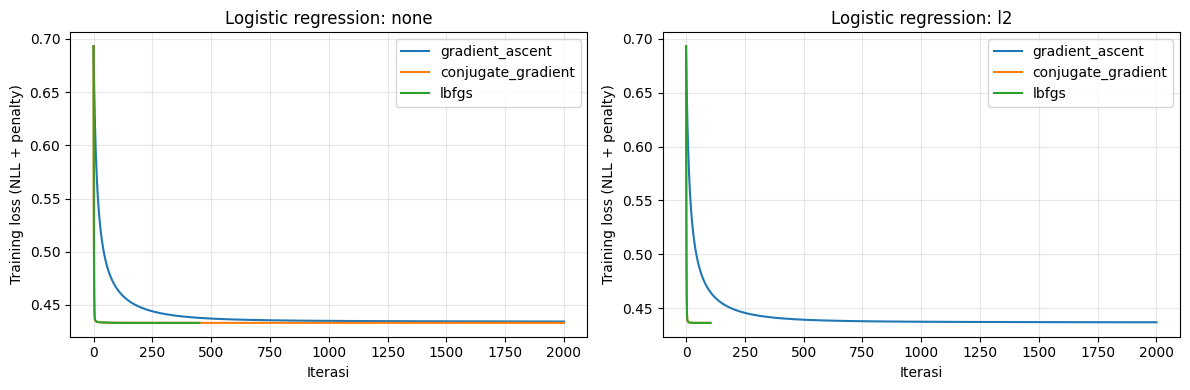

None

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, variant in zip(axes, ['none', 'l2']):
    for solver in ['gradient_ascent', 'conjugate_gradient', 'lbfgs']:
        model = logreg_optimizer_models[(solver, variant)]
        ax.plot(model.loss_history_, label=solver)
    ax.set(xlabel='Iterasi', ylabel='Training loss (NLL + penalty)',
           title=f'Logistic regression: {variant}')
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()


#### Video kontur log-loss dan lintasan parameter
Demonstrasi ini melatih model terpisah dengan satu fitur `days_before_arrival` yang sudah diimputasi dan distandardisasi memakai training split. Dengan demikian, parameter model tepat dua: theta_0 (bias) dan theta_1 (bobot), dan kontur merupakan log-loss pada data training yang sama. Model demonstrasi memakai full-batch gradient ascent tanpa regularisasi. `record_history=True` menyimpan posisi awal dan akhir setiap epoch; garis lintasan serta grafik loss mengikuti history tersebut.

Video arsip ditampilkan dari `docs/figures/logreg_training.mp4`.

In [ ]:
logreg_video_path = ROOT / 'docs' / 'figures' / 'logreg_training.mp4'
display(Video(str(logreg_video_path), embed=True))


#### L2, interaksi kanal, dan ambang

Pada fold pengembangan `exp_*`, baseline dibandingkan dengan varian berpenalti L2 yang menambah interaksi dengan kanal pemesanan. Tabel mencatat pilihan ambang dan jumlah fold yang konvergen.

In [ ]:
# Eksperimen 4: regresi logistik dasar versus L2 dengan interaksi kanal.
def exp_logreg_score(train, y, valid, engineered):
    if engineered:
        train, valid = exp_logreg_features(train), exp_logreg_features(valid)
    numeric = train.select_dtypes(include='number').columns.tolist()
    categorical = [column for column in train.columns if column not in numeric]
    preprocessor = ColumnTransformer([
        ('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric),
        ('categorical', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                                  ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical),
    ])
    a, b = preprocessor.fit_transform(train), preprocessor.transform(valid)
    if engineered:
        names = preprocessor.get_feature_names_out()
        channels = np.flatnonzero(np.char.startswith(names.astype(str), 'categorical__booking_channel_'))
        base = [numeric.index(c) for c in ('log_days_before_arrival', 'log_nightly_rate_idr', 'special_requests')]
        a, b = (np.column_stack([x, *(x[:, c, None] * x[:, channels] for c in base)]) for x in (a, b))
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', message='Logistic regression stopped before convergence')
        model = LogisticRegressionClassifier(
            penalty='l2' if engineered else None, reg_strength=0.001, learning_rate=0.1,
            max_iter=4000 if engineered else 2000, tol=1e-7, random_state=SEED,
        ).fit(a, y)
    exp_logreg_status[engineered].append(model.converged_)
    return model.predict_proba(b)[:, 1]

exp_logreg_status = {False: [], True: []}
exp_logreg_result = exp_compare({'raw': False, 'l2_interactions': True}, exp_logreg_score, exp_cutoffs, inclusive=True)
exp_logreg_result['converged_folds'] = exp_logreg_result['config'].map({
    'raw': sum(exp_logreg_status[False]), 'l2_interactions': sum(exp_logreg_status[True]),
})
print(exp_logreg_result.round(6).to_string(index=False))

### Naive Bayes <a id="naive-bayes"></a>

Naive Bayes dibangun dari nol di `src/models/naive_bayes/naive_bayes.py`. Semua fitur diperlakukan sebagai kategori; fitur kontinu dipotong menjadi bin kuantil yang dipelajari hanya dari data training. Nilai kosong menjadi kategori tersendiri, sehingga baris tidak dibuang atau diimputasi. Model memakai Laplace smoothing dan skor log-probabilitas.

Evaluasi konfigurasi memakai 5-fold cross-validation berkelompok dengan seed 42. Baris fitur yang identik tidak dipisah ke train dan validation. Pemilihan jumlah bin serta alpha dilakukan dari CV, bukan label test.

Bagian berikutnya juga menguji TAN sebagai bonus: tiap fitur memiliki paling banyak satu induk fitur tambahan, sehingga struktur pohon dapat menangkap sebagian ketergantungan yang diabaikan oleh Naive Bayes.


In [ ]:
# Split sama persis dengan SVM (seed, 5 fold, grup baris identik), tetapi memakai seluruh training split.
nb_X_raw = train_df.drop(columns=['is_canceled', 'id'])
nb_y_raw = train_df['is_canceled']
nb_groups = pd.util.hash_pandas_object(nb_X_raw, index=False)
nb_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
nb_train_idx, nb_valid_idx = next(nb_splitter.split(nb_X_raw, nb_y_raw, nb_groups))
assert set(nb_groups.iloc[nb_train_idx]).isdisjoint(nb_groups.iloc[nb_valid_idx])
nb_y_train = nb_y_raw.iloc[nb_train_idx].to_numpy()
nb_y_valid = nb_y_raw.iloc[nb_valid_idx].to_numpy()
print(f'Train: {len(nb_train_idx)}, validation: {len(nb_valid_idx)}')
print(f'Proporsi batal -> train: {nb_y_train.mean():.3f}, validation: {nb_y_valid.mean():.3f}')

In [ ]:
nb_raw_train = nb_X_raw.iloc[nb_train_idx]
nb_raw_valid = nb_X_raw.iloc[nb_valid_idx]
print('Fitur teks:', len(nb_text_features), '| fitur hitungan:', len(nb_count_features),
      '| fitur kontinu:', len(nb_continuous_features))

#### Gaussian atau binning untuk fitur kontinu
Semua konfigurasi memakai `alpha = 1`. `gaussian_log` menerapkan `log1p` sebelum Gaussian karena beberapa fitur sangat miring ke kanan.

### Penanganan nilai kosong
Sekitar 39% baris training dan 39% baris test punya minimal satu nilai kosong, tersebar di 8 kolom. Baris test tidak boleh dibuang karena semua baris harus diprediksi. Tiga cara dibandingkan dengan 5-fold cross-validation (alpha = 1, pada 20 bin dan 5 bin):
- **Dilewati**: NaN dibiarkan, tidak dihitung saat training dan dilewati saat prediksi. Ini sama dengan menjumlahkan fitur yang tidak diketahui sehingga tidak mengubah peluang kelas.
- **Dibuang**: baris training yang punya nilai kosong dibuang. Prediksi tetap melewati nilai kosong karena baris test tidak bisa dibuang.
- **Kategori**: nilai kosong dikodekan `-1` dan dihitung seperti nilai lain.

In [ ]:
print(f"Baris training dengan nilai kosong: {nb_X_raw.isna().any(axis=1).mean():.1%}, "
      f"baris test: {test_df.drop(columns=['id']).isna().any(axis=1).mean():.1%}")
print('Kolom dengan nilai kosong (training):', nb_X_raw.isna().sum()[lambda counts: counts > 0].to_dict())
print(f"P(batal) saat special_requests kosong: {nb_y_raw[nb_X_raw['special_requests'].isna()].mean():.3f}, "
      f"saat terisi: {nb_y_raw[nb_X_raw['special_requests'].notna()].mean():.3f}")

# Lipatan yang sama dengan evaluasi akhir antarmodel (5 fold, seed 42, baris identik dikelompokkan)
nb_cv_folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(nb_X_raw, nb_y_raw, nb_groups))


def nb_cross_validate(n_bins, alpha, missing, drop_incomplete_train=False):
    # Preprocessing dan model dilatih ulang dari nol di tiap lipatan, lalu diukur pada lipatan validasi
    f1_scores = []
    accuracies = []
    recalls = []
    aucs = []
    train_rows = []
    for fold_train, fold_valid in nb_cv_folds:
        raw_fold_train = nb_X_raw.iloc[fold_train]
        y_fold_train = nb_y_raw.iloc[fold_train].to_numpy()
        if drop_incomplete_train:
            complete = ~raw_fold_train.isna().any(axis=1).to_numpy()
            raw_fold_train = raw_fold_train[complete]
            y_fold_train = y_fold_train[complete]
        train_rows.append(len(y_fold_train))
        fold_params = nb_fit_preprocessing(raw_fold_train, n_bins)
        fold_model = NaiveBayesClassifier(alpha=alpha)
        fold_model.fit(nb_transform(raw_fold_train, fold_params, NB_MODE, missing), y_fold_train)
        X_fold_valid = nb_transform(nb_X_raw.iloc[fold_valid], fold_params, NB_MODE, missing)
        y_fold_valid = nb_y_raw.iloc[fold_valid].to_numpy()
        predictions = fold_model.predict(X_fold_valid)
        f1_scores.append(f1_score(y_fold_valid, predictions, average='macro'))
        accuracies.append(accuracy_score(y_fold_valid, predictions))
        recalls.append(recall_score(y_fold_valid, predictions))
        aucs.append(roc_auc_score(y_fold_valid, fold_model.predict_proba(X_fold_valid)[:, 1]))
    return {
        'f1_macro': np.mean(f1_scores), 'f1_macro_std': np.std(f1_scores), 'accuracy': np.mean(accuracies),
        'recall_batal': np.mean(recalls), 'roc_auc': np.mean(aucs), 'f1_per_fold': f1_scores,
        'train_rows': np.mean(train_rows),
    }


nb_missing_settings = [
    ('dilewati', 'skip', False),
    ('dibuang (baris latih)', 'skip', True),
    ('kategori', 'category', False),
]
nb_missing_rows = []
nb_missing_f1 = {}
for nb_bins in [20, 5]:
    for nb_name, nb_missing, nb_drop in nb_missing_settings:
        nb_result = nb_cross_validate(nb_bins, 1.0, nb_missing, nb_drop)
        nb_missing_f1[(nb_bins, nb_name)] = nb_result['f1_per_fold']
        nb_row = {'n_bins': nb_bins, 'cara': nb_name}
        nb_row.update(nb_result)
        del nb_row['f1_per_fold']
        nb_missing_rows.append(nb_row)
nb_missing_table = pd.DataFrame(nb_missing_rows)

# Selisih F1 macro per lipatan terhadap cara "dilewati" (positif berarti lebih baik)
for nb_bins in [20, 5]:
    for nb_name in ['dibuang (baris latih)', 'kategori']:
        nb_difference = np.array(nb_missing_f1[(nb_bins, nb_name)]) - np.array(nb_missing_f1[(nb_bins, 'dilewati')])
        print(f'{nb_bins} bin, {nb_name}: rata-rata selisih {nb_difference.mean():+.4f}, '
              f'lebih baik di {(nb_difference > 0).sum()} dari 5 lipatan')
nb_missing_table

### Pemilihan jumlah bin
Jumlah bin dibandingkan dengan 5-fold cross-validation (nilai kosong sebagai kategori, alpha = 1). Aturan pemilihannya: ambil F1 macro rata-rata tertinggi, dan jika selisihnya lebih kecil daripada simpangan baku antar lipatan, pilih jumlah bin paling sedikit karena modelnya lebih sederhana.

In [ ]:
nb_bins_rows = []
for nb_bins in [5, 10, 20]:
    nb_result = nb_cross_validate(nb_bins, 1.0, 'category')
    nb_row = {'n_bins': nb_bins}
    nb_row.update(nb_result)
    del nb_row['f1_per_fold']
    nb_bins_rows.append(nb_row)
nb_bins_table = pd.DataFrame(nb_bins_rows)

NB_BINS = 5  # jumlah bin terpilih (lihat tabel)
print('jumlah bin terpilih:', NB_BINS)
nb_bins_table

### Pemilihan alpha
`alpha` adalah hitungan pura-pura yang ditambahkan ke setiap nilai fitur dan ke setiap kelas agar tidak ada peluang yang bernilai 0. Nilainya dibandingkan dengan 5-fold cross-validation pada 5 bin. Aturannya: pakai `alpha = 1` (Laplace smoothing standar) kecuali ada nilai lain yang lebih baik dengan selisih lebih besar daripada simpangan baku antar lipatan.

In [ ]:
nb_alphas = [0, 0.1, 0.5, 1, 2, 5, 10]
nb_alpha_rows = []
for nb_alpha in nb_alphas:
    nb_result = nb_cross_validate(NB_BINS, nb_alpha, 'category')
    nb_row = {'alpha': nb_alpha}
    nb_row.update(nb_result)
    del nb_row['f1_per_fold']
    nb_alpha_rows.append(nb_row)
nb_alpha_table = pd.DataFrame(nb_alpha_rows)

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(range(len(nb_alphas)), nb_alpha_table['f1_macro'], yerr=nb_alpha_table['f1_macro_std'], marker='o', capsize=4)
ax.set_xticks(list(range(len(nb_alphas))))
ax.set_xticklabels([str(a) for a in nb_alphas])
ax.set_xlabel('alpha')
ax.set_ylabel('F1 macro (rata-rata dan simpangan baku 5 fold)')
ax.set_title('Pengaruh alpha terhadap performa Naive Bayes')
plt.show()

NB_ALPHA = 1.0  # alpha terpilih (lihat tabel)
print('alpha terpilih:', NB_ALPHA)
nb_alpha_table

### Perbandingan dengan scikit-learn
Kelas dibandingkan dengan `CategoricalNB` pada input yang identik di validation split. Karena nilai kosong sudah menjadi kategori, tidak ada NaN yang perlu diisi. Prior juga di-smoothing dengan `alpha` yang sama, jadi diberikan langsung ke scikit-learn lewat `class_prior`.

In [ ]:
# Bandingkan dengan CategoricalNB scikit-learn pada input yang identik di validation split.
# CategoricalNB butuh kode 0..K-1 per kolom, jadi tiap kolom dikodekan ulang dari nilai training.
# Nilai validation yang tidak pernah ada di training (sangat jarang) diisi dengan modus.
nb_params = nb_fit_preprocessing(nb_raw_train, NB_BINS)
nb_Xtr_bin = nb_transform(nb_raw_train, nb_params, NB_MODE)
nb_Xva_bin = nb_transform(nb_raw_valid, nb_params, NB_MODE)

nb_Xtr_codes = np.full(nb_Xtr_bin.shape, np.nan)
nb_Xva_codes = np.full(nb_Xva_bin.shape, np.nan)
for j in range(nb_Xtr_bin.shape[1]):
    known_values = np.unique(nb_Xtr_bin[~np.isnan(nb_Xtr_bin[:, j]), j])
    code_of = {value: code for code, value in enumerate(known_values)}
    nb_Xtr_codes[:, j] = [code_of.get(v, np.nan) for v in nb_Xtr_bin[:, j]]
    nb_Xva_codes[:, j] = [code_of.get(v, np.nan) for v in nb_Xva_bin[:, j]]
nb_filler = SimpleImputer(strategy='most_frequent')
nb_Xtr_filled = nb_filler.fit_transform(nb_Xtr_codes).astype(int)
nb_Xva_filled = nb_filler.transform(nb_Xva_codes).astype(int)

# Prior juga di-smoothing dengan alpha yang sama, jadi diberikan langsung ke scikit-learn
nb_class_counts = np.bincount(nb_y_train)
nb_smoothed_prior = (nb_class_counts + NB_ALPHA) / (len(nb_y_train) + NB_ALPHA * len(nb_class_counts))
nb_categories = nb_Xtr_filled.max(axis=0) + 1
nb_sk_cat = CategoricalNB(alpha=NB_ALPHA, class_prior=nb_smoothed_prior, min_categories=nb_categories).fit(nb_Xtr_filled, nb_y_train)
nb_own_cat = NaiveBayesClassifier(alpha=NB_ALPHA).fit(nb_Xtr_filled, nb_y_train)
nb_diff_cat = np.abs(nb_sk_cat.predict_proba(nb_Xva_filled) - nb_own_cat.predict_proba(nb_Xva_filled)).max()
print(f'Selisih maksimum predict_proba, buatan sendiri vs CategoricalNB: {nb_diff_cat:.2e}')
print('Nilai validation yang tidak ada di training (diisi modus):', int(np.isnan(nb_Xva_codes).sum()))

nb_compare = []
for nb_name, nb_pair_model in [('CategoricalNB (sklearn)', nb_sk_cat), ('Buatan sendiri', nb_own_cat)]:
    nb_row = {'model': nb_name}
    nb_row.update(nb_evaluate(nb_pair_model, nb_Xva_filled, nb_y_valid))
    nb_compare.append(nb_row)
pd.DataFrame(nb_compare)

Selisih maksimum `predict_proba` hanya sekitar 3,6e-15 dan semua metrik identik (accuracy 0,7843, F1 batal 0,6511, ROC-AUC 0,8319), jadi hasil implementasi sendiri sama dengan scikit-learn. Tidak ada nilai validation yang tidak muncul di training, sehingga tidak ada nilai yang perlu diisi dengan modus.

### Graf hubungan fitur dan kelas
Graf ini menggambarkan struktur Naive Bayes. Kelas `is_canceled` menjadi induk setiap fitur (panah abu-abu), dan tebal panah menunjukkan seberapa banyak informasi yang diberikan fitur tentang kelas (*mutual information*, dalam bit). Garis merah putus-putus bukan bagian dari model: garis itu menghubungkan pasangan fitur yang masih saling bergantung setelah kelas diketahui (*conditional mutual information*), yaitu tempat asumsi independensi Naive Bayes dilanggar. Nilai dihitung pada data training dengan fitur kontinu yang sudah di-binning (5 bin) dan dikoreksi bias agar fitur dengan banyak nilai tidak otomatis tampak lebih berkaitan.

In [ ]:

nb_graph_names = nb_text_features + nb_count_features + nb_continuous_features
nb_graph_params = nb_fit_preprocessing(nb_raw_train, NB_BINS)
nb_graph_X = nb_transform(nb_raw_train, nb_graph_params, NB_MODE)
nb_class_scores, nb_pair_scores = feature_relations(nb_graph_X, nb_y_train, nb_graph_names)

fig, ax = plt.subplots(figsize=(10, 10))
plot_naive_bayes_graph(
    nb_graph_X, nb_y_train, nb_graph_names, class_name='is_canceled', ax=ax,
    title='Graf Naive Bayes: kelas, fitur, dan pasangan fitur yang saling bergantung',
)
plt.show()

print('Informasi tiap fitur tentang kelas (bit), lima terbesar:',
      {name: round(score, 3) for name, score in sorted(nb_class_scores.items(), key=lambda item: item[1], reverse=True)[:5]})
pd.DataFrame(nb_pair_scores[:10], columns=['fitur_a', 'fitur_b', 'cmi_bit'])

Informasi terbesar tentang pembatalan berasal dari `days_before_arrival` (0,139 bit), disusul `special_requests` (0,053 bit) dan `arrival_month` (0,036 bit). Beberapa fitur nyaris tidak berkaitan dengan kelas, misalnya `prior_completed_bookings`, `arrival_day`, `num_children`, dan `room_category`.

Di sisi lain, banyak pasangan fitur yang masih saling bergantung kuat setelah kelas diketahui: `arrival_year` dengan `arrival_month` (0,17 bit), `booking_channel` dengan `special_requests` (0,17 bit), `room_category` dengan `nightly_rate_idr` (0,16 bit), `booking_channel` dengan `nightly_rate_idr` (0,16 bit), serta `weekend_nights` dengan `weekday_nights` (0,16 bit). Naive Bayes mengalikan pasangan seperti ini seolah-olah independen, sehingga bukti yang sama terhitung lebih dari sekali. Hipotesis bahwa hal ini ikut membuat Naive Bayes berada di posisi terakhir diuji pada bagian TAN di bawah.

### Tree Augmented Naive Bayes (bonus)
Graf di atas menunjukkan banyak pasangan fitur yang masih saling bergantung setelah kelas diketahui. Tree Augmented Naive Bayes (TAN) mengurangi asumsi independensi Naive Bayes dengan memberi tiap fitur satu induk fitur tambahan, sehingga fitur-fitur membentuk pohon. Strukturnya dipelajari dari data dengan prosedur Construct-TAN: hitung seberapa bergantung setiap pasangan fitur setelah kelas diketahui (*conditional mutual information*), bangun pohon rentang dengan bobot maksimum, pilih satu akar dan arahkan sisi menjauhi akar, lalu jadikan kelas induk semua fitur. Kelasnya ada di `src/models/naive_bayes/tan.py`.

Sumbernya: Friedman, Geiger, dan Goldszmidt (1997) untuk TAN, Chow dan Liu (1968) untuk pohon ketergantungan, dan Kruskal (1956) untuk pohon rentang. Berbeda dari makalah, nilai kosong dikodekan sebagai kategori (makalah membuang barisnya) dan smoothing bawaan memakai Laplace. Bobot pohon memakai informasi bersama mentah seperti makalah, dan smoothing Dirichlet dari makalah tersedia sebagai opsi.

Konfigurasi dibandingkan dengan 5-fold cross-validation pada lipatan yang sama dengan Naive Bayes. Naive Bayes dengan jumlah bin yang sama dipakai sebagai pembanding berpasangan, dan aturan pemilihannya sama seperti pada Naive Bayes.

In [ ]:


def tan_cross_validate(n_bins, smoothing):
    # Struktur pohon dan tabel peluang dipelajari ulang dari nol di tiap lipatan. Nilai kosong sudah menjadi kategori.
    f1_scores = []
    accuracies = []
    recalls = []
    aucs = []
    fit_seconds = []
    for fold_train, fold_valid in nb_cv_folds:
        raw_fold_train = nb_X_raw.iloc[fold_train]
        y_fold_train = nb_y_raw.iloc[fold_train].to_numpy()
        fold_params = nb_fit_preprocessing(raw_fold_train, n_bins)
        fold_model = TreeAugmentedNaiveBayes(alpha=NB_ALPHA, smoothing=smoothing)
        start_time = time.perf_counter()
        fold_model.fit(nb_transform(raw_fold_train, fold_params, NB_MODE), y_fold_train)
        fit_seconds.append(time.perf_counter() - start_time)
        X_fold_valid = nb_transform(nb_X_raw.iloc[fold_valid], fold_params, NB_MODE)
        y_fold_valid = nb_y_raw.iloc[fold_valid].to_numpy()
        predictions = fold_model.predict(X_fold_valid)
        f1_scores.append(f1_score(y_fold_valid, predictions, average='macro'))
        accuracies.append(accuracy_score(y_fold_valid, predictions))
        recalls.append(recall_score(y_fold_valid, predictions))
        aucs.append(roc_auc_score(y_fold_valid, fold_model.predict_proba(X_fold_valid)[:, 1]))
    return {
        'f1_macro': np.mean(f1_scores), 'f1_macro_std': np.std(f1_scores), 'accuracy': np.mean(accuracies),
        'recall_batal': np.mean(recalls), 'roc_auc': np.mean(aucs), 'fit_seconds': np.mean(fit_seconds),
        'f1_per_fold': f1_scores,
    }


tan_rows = []
tan_f1 = {}
for tan_bins in [5, 10, 20]:
    # Naive Bayes dengan jumlah bin dan nilai kosong yang sama sebagai pembanding berpasangan
    nb_reference = nb_cross_validate(tan_bins, NB_ALPHA, 'category')
    tan_f1[(tan_bins, 'naive bayes')] = nb_reference['f1_per_fold']
    tan_rows.append({
        'n_bins': tan_bins, 'model': 'naive bayes', 'f1_macro': nb_reference['f1_macro'],
        'f1_macro_std': nb_reference['f1_macro_std'], 'accuracy': nb_reference['accuracy'],
        'recall_batal': nb_reference['recall_batal'], 'roc_auc': nb_reference['roc_auc'],
    })
    for tan_smoothing in ['laplace', 'dirichlet']:
        tan_result = tan_cross_validate(tan_bins, tan_smoothing)
        tan_name = 'tan ' + tan_smoothing
        tan_f1[(tan_bins, tan_name)] = tan_result['f1_per_fold']
        tan_row = {'n_bins': tan_bins, 'model': tan_name}
        tan_row.update(tan_result)
        del tan_row['f1_per_fold']
        tan_rows.append(tan_row)
tan_table = pd.DataFrame(tan_rows)

# Selisih F1 macro per lipatan terhadap Naive Bayes dengan jumlah bin yang sama (positif berarti TAN lebih baik)
for tan_bins in [5, 10, 20]:
    for tan_name in ['tan laplace', 'tan dirichlet']:
        tan_difference = np.array(tan_f1[(tan_bins, tan_name)]) - np.array(tan_f1[(tan_bins, 'naive bayes')])
        print(f'{tan_bins} bin, {tan_name}: rata-rata selisih {tan_difference.mean():+.4f}, '
              f'lebih baik di {(tan_difference > 0).sum()} dari 5 lipatan')

TAN_BINS = 5  # jumlah bin terpilih (lihat tabel)
TAN_SMOOTHING = 'laplace'  # smoothing terpilih (lihat tabel)
print('konfigurasi TAN terpilih:', TAN_BINS, 'bin,', TAN_SMOOTHING)
tan_table

TAN lebih baik daripada Naive Bayes pada setiap jumlah bin dan di setiap lipatan: selisih F1 macro sekitar +0,027 pada 5 bin, +0,030 pada 10 bin, dan +0,033 pada 20 bin, jauh lebih besar daripada simpangan baku antar lipatan (sekitar 0,008). ROC-AUC naik dari sekitar 0,835 menjadi 0,867 sampai 0,872. Smoothing Dirichlet dan Laplace hampir tidak berbeda (selisih terbesar 0,0007 pada F1 macro), sehingga dipakai Laplace. F1 macro TAN naik sedikit seiring bertambahnya bin (0,7748, 0,7758, dan 0,7802), tetapi selisih terbesarnya 0,005 masih di bawah simpangan baku. Sesuai aturan pemilihan dipakai **5 bin**, yang juga membuat perbandingan dengan Naive Bayes hanya berbeda pada struktur modelnya.

In [ ]:
# Model final dilatih pada seluruh train.csv dengan konfigurasi terpilih
tan_final_params = nb_fit_preprocessing(nb_X_raw, TAN_BINS)
tan_final_model = TreeAugmentedNaiveBayes(alpha=NB_ALPHA, smoothing=TAN_SMOOTHING)
tan_start = time.perf_counter()
tan_final_model.fit(nb_transform(nb_X_raw, tan_final_params, NB_MODE), nb_y_raw.to_numpy())
print(f'Waktu pelatihan TAN: {time.perf_counter() - tan_start:.1f} detik')

tan_feature_names = nb_text_features + nb_count_features + nb_continuous_features
fig, ax = plt.subplots(figsize=(10, 10))
plot_tan_structure(
    tan_final_model, tan_feature_names, class_name='is_canceled', ax=ax,
    title='Struktur TAN: kelas ke semua fitur dan pohon antarfitur',
)
plt.show()

tan_root_name = tan_feature_names[tan_final_model.parents_.index(None)]
print('Akar pohon:', tan_root_name)
pd.DataFrame(
    [(tan_feature_names[parent], tan_feature_names[child], weight) for parent, child, weight in tan_final_model.edges_],
    columns=['induk', 'anak', 'cmi_bit'],
)

Model final dilatih pada seluruh `train.csv` dalam sekitar 7 detik. Akar pohon adalah `days_before_arrival`, fitur yang paling berkaitan dengan kelas. Pohon yang terbentuk memuat banyak pasangan yang tampak pada graf Naive Bayes, misalnya `arrival_month` dengan `arrival_year`, `booking_channel` dengan `special_requests`, `weekday_nights` dengan `weekend_nights`, dan `nightly_rate_idr` dengan `room_category`. Dengan 16 sisi untuk 17 fitur, tiap fitur selain akar mendapat tepat satu induk fitur.

### K-Nearest Neighbors (KNN) <a id="knn"></a>

KNN dibangun dari nol di src/models/knn/knn.py. Model ini tidak mempelajari parameter apa pun saat training. Seluruh data training hanya disimpan, lalu setiap data baru diklasifikasikan dengan melihat k data training yang jaraknya paling dekat. Jarak yang dipakai adalah jarak Euclidean.

Ada dua cara menggabungkan suara tetangga. Pada bobot uniform, setiap tetangga bernilai satu suara. Pada bobot distance, suara tetangga dibagi jaraknya sehingga tetangga yang lebih dekat lebih berpengaruh. Jika ada tetangga dengan jarak nol, hanya tetangga tersebut yang dihitung. Jika jumlah suara seri, kelas pertama yang dipilih.

Menghitung jarak ke seluruh data training sekaligus membutuhkan memori sekitar 30 GB untuk validation set. Karena itu jarak dihitung per batch 512 baris. Hasilnya tetap sama persis dengan perhitungan langsung.

Split validation sama dengan model lain (seed 42, 5 fold, baris identik dikelompokkan) dan memakai seluruh training split. Metrik utama yang dipakai adalah F1 macro, sama dengan metrik leaderboard Kaggle.

Bagian ini menyetel skala dan parameter model KNN pada percobaan awal. Pada [uji lintas model](#pemilihan-fitur), model juga menguji kelompok `knn` sebagai masukan; jarak untuk membangun kelompok fitur itu dihitung terpisah dari pemungutan suara model akhir.

In [ ]:
knn_y_raw = train_df['is_canceled'].to_numpy()
knn_groups = pd.util.hash_pandas_object(knn_X_raw, index=False)
knn_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
knn_train_idx, knn_valid_idx = next(knn_splitter.split(knn_X_raw, knn_y_raw, knn_groups))
assert set(knn_groups.iloc[knn_train_idx]).isdisjoint(knn_groups.iloc[knn_valid_idx])
knn_y_train, knn_y_valid = knn_y_raw[knn_train_idx], knn_y_raw[knn_valid_idx]
print(f'Train: {len(knn_train_idx)}, validation: {len(knn_valid_idx)}')

In [ ]:
def knn_evaluate(model, X, y):
    probabilities = model.predict_proba(X)[:, 1]
    predictions = (probabilities > 0.5).astype(int)  # sama dengan predict(), seri dimenangkan kelas 0
    return {
        'accuracy': accuracy_score(y, predictions),
        'precision': precision_score(y, predictions, zero_division=0),
        'recall': recall_score(y, predictions, zero_division=0),
        'f1': f1_score(y, predictions, zero_division=0),
        'f1_macro': f1_score(y, predictions, average='macro'),
        'roc_auc': roc_auc_score(y, probabilities),
    }

#### Pemilihan scaling, k, dan bobot
Setiap kombinasi scaling, jumlah tetangga k, dan cara pembobotan dievaluasi pada validation. k yang kecil membuat model sangat peka terhadap satu atau dua tetangga, sedangkan k yang besar membuat batas keputusan lebih halus tetapi bisa ikut terpengaruh data yang jauh.

In [ ]:
KNN_SCALINGS = ['standard', 'minmax', 'log_standard']
KNN_KS = [1, 5, 11, 21, 31, 51]
KNN_WEIGHT_OPTIONS = ['uniform', 'distance']

knn_grid_rows = []
for scaling in KNN_SCALINGS:
    preprocessor = knn_make_preprocessor(scaling)
    X_train = preprocessor.fit_transform(knn_X_raw.iloc[knn_train_idx])
    X_valid = preprocessor.transform(knn_X_raw.iloc[knn_valid_idx])
    for k in KNN_KS:
        for weights in KNN_WEIGHT_OPTIONS:
            model = KNNClassifier(n_neighbors=k, weights=weights).fit(X_train, knn_y_train)
            knn_grid_rows.append({'scaling': scaling, 'k': k, 'weights': weights,
                                  **knn_evaluate(model, X_valid, knn_y_valid)})
knn_grid = pd.DataFrame(knn_grid_rows)

fig, ax = plt.subplots(figsize=(8, 4.5))
for (scaling, weights), part in knn_grid.groupby(['scaling', 'weights'], sort=False):
    ax.plot(part['k'], part['f1_macro'], marker='o', linestyle='-' if weights == 'distance' else '--',
            label=f'{scaling}, {weights}')
ax.set_xlabel('k (jumlah tetangga)')
ax.set_ylabel('F1 macro pada validation')
ax.set_title('Pengaruh scaling, k, dan bobot terhadap KNN')
ax.legend(fontsize=8)
plt.show()

knn_best = knn_grid.loc[knn_grid['f1_macro'].idxmax()]
KNN_SCALING, KNN_K, KNN_WEIGHTS = knn_best['scaling'], int(knn_best['k']), knn_best['weights']
print(f'Terpilih: scaling {KNN_SCALING}, k = {KNN_K}, bobot {KNN_WEIGHTS}')
knn_grid.sort_values('f1_macro', ascending=False).head(8).reset_index(drop=True)

#### Insight
- Bobot distance selalu sama atau lebih baik daripada uniform. Pada bobot uniform, F1 macro turun saat k membesar hingga sekitar 0,79 pada k = 51, sedangkan bobot distance tetap di kisaran 0,83 sampai 0,84 karena tetangga yang jauh hanya mendapat suara kecil.
- Standard scaling dengan k = 31 memberi F1 macro tertinggi, yaitu 0,841. Minmax paling baik 0,838 pada k = 11 sehingga selisih keduanya kecil.
- log_standard paling buruk pada hampir semua k. Log memperkecil perbedaan lead time dan harga yang besar, padahal perbedaan itu termasuk sinyal terkuat untuk membedakan booking yang batal.

#### Perbandingan dengan scikit-learn
Model terpilih dibandingkan dengan KNeighborsClassifier dari scikit-learn dengan parameter yang sama dan pencarian brute force. Hasil keduanya hanya bisa berbeda ketika ada beberapa tetangga dengan jarak yang sama persis di batas tetangga ke-k, karena urutan pemilihan tetangga yang seri bisa berbeda.

In [ ]:
knn_preprocessor = knn_make_preprocessor(KNN_SCALING)
knn_X_train = knn_preprocessor.fit_transform(knn_X_raw.iloc[knn_train_idx])
knn_X_valid = knn_preprocessor.transform(knn_X_raw.iloc[knn_valid_idx])

knn_model = KNNClassifier(n_neighbors=KNN_K, weights=KNN_WEIGHTS)
knn_sklearn = KNeighborsClassifier(n_neighbors=KNN_K, weights=KNN_WEIGHTS, algorithm='brute')
knn_compare, knn_probabilities = [], {}

for knn_name, knn_candidate in [('KNNClassifier (custom)', knn_model), ('KNeighborsClassifier (scikit-learn)', knn_sklearn)]:
    knn_start = time.perf_counter()
    knn_candidate.fit(knn_X_train, knn_y_train)
    knn_probabilities[knn_name] = knn_candidate.predict_proba(knn_X_valid)[:, 1]
    knn_seconds = time.perf_counter() - knn_start
    knn_compare.append({'model': knn_name, **knn_evaluate(knn_candidate, knn_X_valid, knn_y_valid), 'fit_predict_seconds': knn_seconds})

knn_diff = np.abs(knn_probabilities['KNNClassifier (custom)'] - knn_probabilities['KNeighborsClassifier (scikit-learn)'])
print(f'Selisih maksimum P(batal): {knn_diff.max():.4f}')
print(f'Baris validation dengan P(batal) berbeda: {(knn_diff > 1e-9).sum()} dari {len(knn_diff)}')
pd.DataFrame(knn_compare)

#### Bobot fitur, jumlah tetangga, dan ambang

Pada fold pengembangan `exp_*`, percobaan pertama menyetel bobot fitur. Percobaan kedua memakai bobot terpilih untuk membandingkan jumlah tetangga dan ambang.

In [ ]:
# Eksperimen 1: bobot fitur KNN dengan jumlah tetangga tetap.
exp_weight_columns = ['days_before_arrival', 'nightly_rate_idr', 'special_requests']
exp_weight_sets = {
    'equal': {},
    'moderate': dict(zip(exp_weight_columns, (2, 2, 1.5))),
    'strong': dict(zip(exp_weight_columns, (3, 3, 2))),
    'stronger': dict(zip(exp_weight_columns, (4, 4, 3))),
    'calendar': dict(zip(exp_weight_columns, (3, 3, 2)), arrival_month=2, arrival_day=2),
}
exp_weights_result = exp_compare(
    {name: (31, weights) for name, weights in exp_weight_sets.items()}, exp_knn_score, [0.5],
)
print(f'scikit-learn {sklearn_version}; development={len(exp_dev)}, holdout={len(exp_holdout)}')
print(exp_weights_result.round(6).to_string(index=False))

In [ ]:
# Eksperimen 2: jumlah tetangga dan ambang KNN dengan bobot terpilih.
exp_selected_weights = exp_weight_sets[exp_weights_result.loc[0, 'config']]
exp_neighbors_result = exp_compare(
    {k: (k, exp_selected_weights) for k in (7, 15, 23, 31, 47, 63)},
    exp_knn_score, exp_cutoffs,
)
print(exp_neighbors_result.round(6).to_string(index=False))

### Hasil eksperimen `exp_*`: KNN berbobot

Pilihan KNN di sini merangkum perbandingan historis antara KNN, C4.5, regresi logistik, dan SVM. Skor holdout dilaporkan dengan konfigurasi yang sudah ditetapkan. Hasil ini bukan konfigurasi ekspor; KNN untuk submisi memakai `fe_winners` dari [pencarian fitur bersama](#pemilihan-fitur).

In [ ]:
# Model tunggal terpilih: KNN berbobot, k=15, ambang 0,475.
exp_final_config = (15, dict(zip(exp_weight_columns, (2, 2, 1.5))))
exp_final_cutoff = 0.475
exp_winner = exp_neighbors_result.iloc[0]
assert exp_winner['config'] == exp_final_config[0] and exp_winner['cutoff'] == exp_final_cutoff
assert exp_winner['macro_f1'] == max(table.loc[0, 'macro_f1'] for table in (
    exp_weights_result, exp_neighbors_result, exp_tree_result, exp_logreg_result, exp_svm_result,
))

for name, config, cutoff in [('KNN awal', (31, {}), 0.5), ('KNN terpilih', exp_final_config, exp_final_cutoff)]:
    scores = exp_knn_score(exp_X.iloc[exp_dev], exp_y[exp_dev], exp_X.iloc[exp_holdout], config)
    score = f1_score(exp_y[exp_holdout], scores > cutoff, average='macro')
    print(f'{name}: Macro F1 holdout = {score:.6f}')



### Pemilihan fitur lintas model (eksplorasi) <a id="pemilihan-fitur"></a>

#### Ablation dan pemilihan kandidat

Kandidat mencakup baseline bersama, tiap kelompok secara terpisah, dan beberapa gabungan yang ditetapkan di muka. Contohnya, `calendar + behavior` memasangkan konteks waktu kedatangan dan perilaku pemesanan, sedangkan `te + knn` menggabungkan ringkasan historis berdasarkan kategori dan kemiripan.

Konfigurasi estimator ditahan tetap dalam setiap perbandingan. Untuk tiap model, kombinasi dengan rata-rata F1 makro tertinggi pada fold pengembangan dipilih; jika seri, kombinasi yang lebih ringkas diutamakan. Baseline boleh menang. Pencarian ini tidak mencakup seluruh himpunan kombinasi yang mungkin.

In [ ]:
fe_cv, fe_winners = select_feature_groups(
    fe_X.iloc[fe_dev],
    fe_y[fe_dev],
    seed=FE_SEED,
    train_limit=FE_CV_LIMIT,
)


fe_cv_by_choice = fe_cv.set_index(['model', 'candidate'])
fe_selected_cv = []
for model, groups in fe_winners.items():
    candidate = '+'.join(groups) or 'base'
    fe_cv_row = fe_cv_by_choice.loc[(model, candidate)]
    fe_selected_cv.append({
        'model': model,
        'kelompok terpilih': ' + '.join(groups) or 'dasar saja',
        'f1_cv_dasar': fe_cv_by_choice.loc[(model, 'base'), 'mean_macro_f1'],
        'f1_cv_terpilih': fe_cv_row['mean_macro_f1'],
        'simpangan_baku_fold': np.std(fe_cv_row['fold_scores']),
    })

pd.DataFrame(fe_selected_cv).round(6)

#### Evaluasi pada holdout

Kombinasi terpilih dan baseline bersama dilatih ulang pada subset pengembangan yang sama. F1 makro holdout dilaporkan setelah pemilihan selesai dan tidak dipakai untuk mengganti kombinasi. Baseline bersama dapat berbeda dari prapemrosesan khusus model pada percobaan awal.

In [ ]:
fe_holdout_results = evaluate_feature_choices(
    fe_X.iloc[fe_dev],
    fe_y[fe_dev],
    fe_X.iloc[fe_holdout],
    fe_y[fe_holdout],
    fe_winners,
    seed=FE_SEED,
    train_limit=FE_REFIT_LIMIT,
)

# Selisih positif berarti kombinasi terpilih mengungguli fitur dasar.
fe_holdout_results['delta_f1'] = (
    fe_holdout_results['selected_holdout_f1'] - fe_holdout_results['base_holdout_f1']
)
fe_holdout_results.round(6)

#### Catatan hasil

> Pilihan fitur berlaku pada daftar kandidat, konfigurasi, dan ukuran sampel di atas. Selisih pada holdout mengukur manfaat prediktif pada partisi tersebut, bukan efek kausal suatu fitur atau jaminan bahwa kombinasi yang sama paling baik pada periode lain.

## Perbandingan model dan analisis biaya <a id="model-comparison"></a>

Lima baseline dibandingkan pada lima fold berkelompok. TAN dilaporkan terpisah sebagai eksperimen bonus berpasangan dan tidak ikut dalam lima model atau ekspor akhir. Prediksi *out-of-fold* yang sama mendasari matriks konfusi dan analisis biaya. Bagian ini tidak memilih model ekspor.

### Performa baseline pada lima fold


Bagian ini mempertahankan perbandingan model dengan alur dan prapemrosesan percobaan awal. Hasil ablation yang memakai baseline bersama dilaporkan secara terpisah di [pemilihan fitur](#pemilihan-fitur).

In [ ]:
# Evaluasi akhir memakai 5-fold cross-validation penuh. Fold pertama sama dengan validation
# di tiap bagian model, dan konfigurasi tiap model diambil dari bagiannya masing-masing.
cv_X_raw = train_df.drop(columns=['is_canceled', 'id'])
cv_y = train_df['is_canceled'].to_numpy()
cv_groups = pd.util.hash_pandas_object(cv_X_raw, index=False)
cv_folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(cv_X_raw, cv_y, cv_groups))
for valid_idx in (svm_valid_indices, logreg_valid_idx, nb_valid_idx, dtl_valid_idx, knn_valid_idx):
    assert np.array_equal(np.sort(valid_idx), np.sort(cv_folds[0][1]))

svm_custom_table = svm_results[svm_results['backend'] == 'custom']
svm_best = svm_custom_table.loc[svm_custom_table['f1'].idxmax()]
svm_best_model = svm_custom_models[(svm_best['solver'], svm_best['kernel'])]

logreg_custom_table = logreg_results[logreg_results['implementation'] == 'custom']
logreg_best = logreg_custom_table.loc[logreg_custom_table['f1'].idxmax()]
logreg_best_model = logreg_custom_models[logreg_best['variant']]


# Setiap fungsi melatih ulang model dari nol pada train fold, termasuk preprocessing,
# lalu mengembalikan prediksi kelas dan skor (peluang atau decision function) pada validation fold
def cv_c45(train_idx, valid_idx):
    X = dtl_preprocess(cv_X_raw, dtl_fit_rare(cv_X_raw.iloc[train_idx]))
    model = dtl_train(X, dtl_y_raw, dtl_groups, train_idx, DTL_FACTOR)
    X_valid = X.iloc[valid_idx]
    return model.predict(X_valid), dtl_predict_proba(model, X_valid)[:, 1]


def cv_knn(train_idx, valid_idx):
    preprocessor = knn_make_preprocessor(KNN_SCALING)
    model = KNNClassifier(n_neighbors=KNN_K, weights=KNN_WEIGHTS)
    model.fit(preprocessor.fit_transform(cv_X_raw.iloc[train_idx]), cv_y[train_idx])
    proba = model.predict_proba(preprocessor.transform(cv_X_raw.iloc[valid_idx]))[:, 1]
    return (proba > 0.5).astype(int), proba  # sama dengan predict(), seri dimenangkan kelas 0


def cv_svm(train_idx, valid_idx):
    if SVM_TRAIN_LIMIT is not None and len(train_idx) > SVM_TRAIN_LIMIT:
        train_idx, _ = train_test_split(train_idx, train_size=SVM_TRAIN_LIMIT,
                                        stratify=cv_y[train_idx], random_state=SEED)
    preprocessor, model = clone(svm_preprocessor), clone(svm_best_model)
    model.fit(preprocessor.fit_transform(cv_X_raw.iloc[train_idx]), cv_y[train_idx])
    X_valid = preprocessor.transform(cv_X_raw.iloc[valid_idx])
    return model.predict(X_valid), model.decision_function(X_valid)


def cv_logreg(train_idx, valid_idx):
    preprocessor, model = clone(logreg_preprocessor), clone(logreg_best_model)
    model.fit(preprocessor.fit_transform(cv_X_raw.iloc[train_idx]), cv_y[train_idx])
    X_valid = preprocessor.transform(cv_X_raw.iloc[valid_idx])
    return model.predict(X_valid), model.predict_proba(X_valid)[:, 1]


def cv_naive_bayes(train_idx, valid_idx):
    params = nb_fit_preprocessing(cv_X_raw.iloc[train_idx], NB_BINS or 10)
    model = NaiveBayesClassifier(alpha=NB_ALPHA)
    model.fit(nb_transform(cv_X_raw.iloc[train_idx], params, NB_MODE, 'category'), cv_y[train_idx])
    X_valid = nb_transform(cv_X_raw.iloc[valid_idx], params, NB_MODE, 'category')
    return model.predict(X_valid), model.predict_proba(X_valid)[:, 1]


cv_models = {
    'C4.5': (f'REP + oversampling x{DTL_FACTOR}', cv_c45),
    'KNN': (f'{KNN_SCALING}, k = {KNN_K}, bobot {KNN_WEIGHTS}', cv_knn),
    'SVM': (f"{svm_best['solver']} / {svm_best['kernel']}, {SVM_TRAIN_LIMIT} baris", cv_svm),
    'Logistic Regression': (f"penalti {logreg_best['variant']}", cv_logreg),
    'Naive Bayes': (f'binning {NB_BINS} bin, alpha {NB_ALPHA}', cv_naive_bayes),
}

warnings.filterwarnings('ignore', message='Logistic regression stopped before convergence')
cv_rows, final_predictions, final_scores = [], {}, {}
for model_name, (variant, run_fold) in cv_models.items():
    out_of_fold = np.zeros(len(cv_y), dtype=int)  # prediksi tiap baris saat baris itu menjadi validation
    out_of_fold_scores = np.zeros(len(cv_y), dtype=float)
    for fold, (train_idx, valid_idx) in enumerate(cv_folds, start=1):
        started = time.perf_counter()
        predictions, scores = run_fold(train_idx, valid_idx)
        predictions = np.asarray(predictions).astype(int)
        out_of_fold[valid_idx] = predictions
        out_of_fold_scores[valid_idx] = scores
        y_valid = cv_y[valid_idx]
        cv_rows.append({
            'model': model_name, 'varian': variant, 'fold': fold,
            'accuracy': accuracy_score(y_valid, predictions),
            'precision': precision_score(y_valid, predictions, zero_division=0),
            'recall': recall_score(y_valid, predictions, zero_division=0),
            'f1': f1_score(y_valid, predictions, zero_division=0),
            'f1_macro': f1_score(y_valid, predictions, average='macro'),
            'roc_auc': roc_auc_score(y_valid, scores),
            'seconds': time.perf_counter() - started,
        })
    final_predictions[model_name] = (cv_y, out_of_fold)
    final_scores[model_name] = (cv_y, out_of_fold_scores)
    print(f'{model_name}: selesai')

cv_fold_results = pd.DataFrame(cv_rows)
final_metrics = ['accuracy', 'precision', 'recall', 'f1', 'f1_macro', 'roc_auc']
cv_grouped = cv_fold_results.groupby(['model', 'varian'], sort=False)[final_metrics]
final_results = cv_grouped.mean().join(cv_grouped.std(), rsuffix='_std').reset_index()
final_results = final_results.sort_values('f1_macro', ascending=False).reset_index(drop=True)

# Tampilan rata-rata ± simpangan baku dari 5 fold
final_results[['model', 'varian']].assign(**{
    metric: final_results[metric].map('{:.3f}'.format) + ' ± ' + final_results[f'{metric}_std'].map('{:.3f}'.format)
    for metric in final_metrics
})

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={'width_ratios': [1.3, 1]})
final_table = final_results.set_index('model')
final_table[final_metrics].plot.bar(
    ax=axes[0], rot=0, width=0.8,
    yerr=final_table[[f'{metric}_std' for metric in final_metrics]].to_numpy().T, capsize=2,
)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel('rata-rata 5-fold CV')
axes[0].set_title('Perbandingan metrik antarmodel (garis hitam = simpangan baku antarfold)')
axes[0].legend(loc='lower right', ncol=3, fontsize=8)

final_baseline = 1 - cv_y.mean()
axes[1].barh(final_results['model'], final_results['accuracy'], xerr=final_results['accuracy_std'],
             color='#4C72B0', capsize=3)
axes[1].axvline(final_baseline, color='#C44E52', linestyle='--', label=f'selalu tebak tidak batal ({final_baseline:.3f})')
axes[1].set_xlim(0.5, 1)
axes[1].invert_yaxis()
axes[1].set_xlabel('accuracy')
axes[1].set_title('Accuracy dibanding baseline')
axes[1].legend(loc='lower right', fontsize=8)
fig.tight_layout()
plt.show()

# Confusion matrix dari prediksi out-of-fold, setiap baris train.csv diprediksi tepat satu kali
fig, axes = plt.subplots(1, len(final_predictions), figsize=(4 * len(final_predictions), 3.6))
for ax, model_name in zip(axes, final_results['model']):
    y_true, predictions = final_predictions[model_name]
    ConfusionMatrixDisplay(confusion_matrix(y_true, predictions), display_labels=['tidak batal', 'batal']).plot(
        ax=ax, colorbar=False, values_format='d'
    )
    ax.set_title(model_name)
fig.tight_layout()
plt.show()

- KNN dan C4.5 berada di posisi teratas dengan F1 macro 0,832 ± 0,008 dan 0,830 ± 0,006. Selisih keduanya jauh lebih kecil daripada variasi antarfold. KNN unggul di tiga fold dan C4.5 di dua fold, sehingga keduanya dapat dianggap setara.
- Perbedaan terbesar keduanya ada pada roc_auc, yaitu 0,914 untuk KNN dan 0,865 untuk C4.5. Peluang KNN berasal dari 31 tetangga yang diberi bobot jarak sehingga nilainya halus. Peluang C4.5 hanya berasal dari proporsi kelas di leaf tempat booking itu jatuh sehingga nilainya lebih kasar.
- Logistic Regression dan SVM hampir sama, dengan F1 macro 0,759 dan 0,754. Hal ini wajar karena SVM terbaik memakai kernel linear, sehingga keduanya sama-sama mencari batas keputusan berupa garis lurus. SVM hanya dilatih dengan 1.000 baris per fold, tetapi hasilnya tetap dekat dengan Logistic Regression yang memakai seluruh train fold.
- Naive Bayes menganggap setiap fitur saling independen, padahal ada fitur yang saling berkaitan. TAN pada bagian bonus menguji struktur yang mengurangi asumsi ini; hasilnya berasal dari CV pasangan dengan Naive Bayes dan tidak dicampur ke tabel perbandingan baseline lima model.
- C4.5 dan KNN unggul karena keduanya bisa menangkap pola yang tidak linear. C4.5 memeriksa fitur secara berbeda di tiap cabang, sedangkan KNN mencari booking lain yang mirip di banyak fitur sekaligus. Model linear hanya memberi satu bobot untuk setiap fitur sehingga interaksi seperti ini sulit ditangkap.
- Semua model jauh di atas baseline 0,675, tetapi recall-nya hanya 0,60 sampai 0,74. Artinya sekitar 26 sampai 40% booking yang batal belum terdeteksi. Jika hotel lebih mementingkan antisipasi pembatalan, threshold prediksi dapat diturunkan untuk menaikkan recall dengan konsekuensi precision turun.
- Fold pertama memberi skor tertinggi untuk semua model. Kemungkinan sebagian karena konfigurasi tiap model dipilih dengan fold ini, sehingga angka di bagian masing-masing model sedikit optimistis. Rata-rata 5 fold di atas lebih dapat dipercaya untuk membandingkan model.

### Klasifikasi berbasis biaya

Pada persoalan, kelas 1 berarti booking **batal**. False Positive berarti model mengatakan batal untuk booking yang sebenarnya tidak batal. Hotel dapat mengira kamar akan kosong dan menerima booking tambahan, sehingga berisiko overbooked. Karena itu biaya False Positive ditetapkan 2, sedangkan biaya False Negative adalah 1. Untuk peluang pembatalan yang terkalibrasi $p=P(y=1\mid x)$, biaya prediksi batal adalah $2(1-p)$ dan biaya prediksi tidak batal adalah $p$. Model memilih batal bila $2(1-p)\leq p$, sehingga threshold berubah dari 0,5 menjadi $2/3\approx0,667$. Threshold lebih tinggi mengurangi False Positive, meskipun False Negative dapat bertambah.

In [ ]:
FP_COST, FN_COST = 2.0, 1.0
COST_THRESHOLD = cost_sensitive_threshold(FP_COST, FN_COST)
probabilistic_models = ['C4.5', 'KNN', 'Logistic Regression', 'Naive Bayes']
cost_rows, excluded_models = [], {}

for model_name in probabilistic_models:
    y_true, probabilities = final_scores[model_name]
    probabilities = np.asarray(probabilities, dtype=float)
    # Cost threshold hanya sah untuk peluang P(batal) yang valid, bukan decision score mentah.
    if probabilities.ndim != 1 or not np.isfinite(probabilities).all() or np.any((probabilities < 0) | (probabilities > 1)):
        excluded_models[model_name] = (np.nanmin(probabilities), np.nanmax(probabilities))
        continue
    default_predictions = (probabilities >= 0.5).astype(int)
    cost_predictions = predict_cost_sensitive(probabilities, FP_COST, FN_COST)
    default = classification_cost(y_true, default_predictions, FP_COST, FN_COST)
    cost_sensitive = classification_cost(y_true, cost_predictions, FP_COST, FN_COST)
    cost_rows.extend([
        {'model': model_name, 'threshold': 0.5, **default},
        {'model': model_name, 'threshold': COST_THRESHOLD, **cost_sensitive},
    ])

if not cost_rows:
    raise RuntimeError('Tidak ada model dengan probabilitas P(batal) yang valid untuk evaluasi cost-sensitive.')
if excluded_models:
    print('Model dikeluarkan karena skor bukan probabilitas [0, 1]:', excluded_models)

cost_results = pd.DataFrame(cost_rows)
cost_results['cost_per_booking'] = cost_results['total_cost'] / len(cv_y)

print(f'Threshold cost-sensitive: {COST_THRESHOLD:.3f} (C_FP={FP_COST:g}, C_FN={FN_COST:g})')
cost_results.sort_values(['model', 'threshold']).reset_index(drop=True)

In [ ]:
# Visualisasi perubahan kesalahan pada model probabilistik dengan total biaya terendah.
best_cost_model = cost_results.loc[cost_results['threshold'] == COST_THRESHOLD].sort_values('total_cost').iloc[0]['model']
y_cost, p_cost = final_scores[best_cost_model]
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
for ax, threshold in zip(axes, [0.5, COST_THRESHOLD]):
    predictions = (p_cost >= threshold).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_cost, predictions), display_labels=['tidak batal', 'batal']).plot(
        ax=ax, colorbar=False, values_format='d'
    )
    report = classification_cost(y_cost, predictions, FP_COST, FN_COST)
    ax.set_title(f'{best_cost_model}, threshold {threshold:.3f}\nbiaya = {report["total_cost"]:.0f}')
fig.tight_layout()
plt.show()

### Analisis

Tabel membandingkan prediksi out-of-fold pada threshold standar dan threshold cost-sensitive, sehingga setiap booking dievaluasi oleh model yang tidak melatihnya. Ukuran utama pada bonus ini adalah `total_cost = 2 × FP + 1 × FN`, bukan accuracy atau F1. Threshold 0,667 lebih konservatif dalam menyatakan booking akan batal. Akibatnya jumlah FP seharusnya turun, tetapi jumlah FN dapat naik. Pilihan yang tepat adalah konfigurasi dengan total biaya paling rendah, sambil tetap melaporkan perubahan confusion matrix agar trade-off operasionalnya transparan.

## Pelatihan ulang dan ekspor <a id="final-fit"></a>

Keputusan di bawah berasal dari CV pengembangan, bukan holdout atau label test. C4.5 memakai REP tanpa oversampling; SVM memakai keputusan CV berpasangan dengan baseline iterasi 04 (16.000 baris); KNN, regresi logistik, dan Naive Bayes memakai `fe_winners`. Kandidat, fitur, ambang, dan sumber ditampilkan sebelum refit.


In [ ]:
fe_final_choices = {name: fe_winners[name] for name in ('knn', 'logreg', 'naive_bayes')}
final_fit_decisions = pd.DataFrame([
    {'Model': 'C4.5', 'Kandidat': str(dtl_c45_top['candidate']), 'Fitur': '+'.join(next(groups for name, groups in DTL_C45_CANDIDATES if name == str(dtl_c45_top['candidate']))) or 'dasar', 'Ambang': 'kelas daun', 'Sumber keputusan': 'pemenang CV berpasangan; REP tanpa oversampling'},
    {'Model': 'SVM', 'Kandidat': paired_svm_winner, 'Fitur': '+'.join(paired_svm_candidates.get(paired_svm_winner, ())) or 'dasar', 'Ambang': paired_svm_cutoff, 'Sumber keputusan': 'CV berpasangan; baseline iterasi 04, 16.000 baris'},
    *[{'Model': name, 'Kandidat': '+'.join(groups) or 'dasar', 'Fitur': '+'.join(groups) or 'dasar', 'Ambang': 'default model', 'Sumber keputusan': 'fe_winners dari CV pengembangan'} for name, groups in fe_final_choices.items()],
])
display(final_fit_decisions)


In [ ]:
# Refit pemenang CV dengan grow/prune REP tanpa oversampling, lalu prediksi test.
dtl_c45_winner_name = str(dtl_c45_top["candidate"])  # tidak memilih ulang dari hasil holdout
dtl_c45_winner_groups = next(groups for name, groups in DTL_C45_CANDIDATES
                             if name == dtl_c45_winner_name)
dtl_c45_all_idx = np.arange(len(dtl_X_raw))
dtl_c45_all_rare = dtl_fit_rare(dtl_X_raw)
dtl_c45_all_X = dtl_preprocess(dtl_X_raw, dtl_c45_all_rare)
dtl_c45_all_grow_idx, dtl_c45_all_prune_idx = dtl_grow_prune_split(
    dtl_c45_all_X, dtl_y_raw, dtl_groups, dtl_c45_all_idx
)
dtl_c45_test_raw = test_df.drop(columns=["id"])
dtl_c45_test_X = dtl_preprocess(dtl_c45_test_raw, dtl_c45_all_rare).reset_index(drop=True)
dtl_c45_all_X_grow = dtl_c45_all_X.iloc[dtl_c45_all_grow_idx].reset_index(drop=True)
dtl_c45_all_X_prune = dtl_c45_all_X.iloc[dtl_c45_all_prune_idx].reset_index(drop=True)
if dtl_c45_winner_groups:
    dtl_c45_query_raw = pd.concat([
        dtl_X_raw.iloc[dtl_c45_all_prune_idx], dtl_c45_test_raw
    ], ignore_index=True)
    dtl_c45_all_blocks = build_blocks(
        dtl_X_raw.iloc[dtl_c45_all_grow_idx],
        dtl_y_raw.iloc[dtl_c45_all_grow_idx].to_numpy(),
        dtl_c45_query_raw, set(dtl_c45_winner_groups), seed=SEED
    )
    dtl_c45_train_map = {name: (dtl_c45_all_blocks[name][0], dtl_c45_all_blocks[name][0])
                         for name in dtl_c45_winner_groups}
    dtl_c45_query_map = {name: (dtl_c45_all_blocks[name][1], dtl_c45_all_blocks[name][1])
                         for name in dtl_c45_winner_groups}
    dtl_c45_all_X_grow = dtl_c45_append_blocks(
        dtl_c45_all_X_grow, dtl_c45_train_map, dtl_c45_winner_groups
    )
    dtl_c45_query_X = dtl_c45_append_blocks(
        pd.concat([dtl_c45_all_X_prune, dtl_c45_test_X], ignore_index=True),
        dtl_c45_query_map, dtl_c45_winner_groups
    )
    dtl_c45_all_X_prune = dtl_c45_query_X.iloc[:len(dtl_c45_all_prune_idx)].reset_index(drop=True)
    dtl_c45_test_X = dtl_c45_query_X.iloc[len(dtl_c45_all_prune_idx):].reset_index(drop=True)
dtl_c45_final_model = dtl_c45_fit_rep(
    dtl_c45_all_grow_idx, dtl_c45_all_prune_idx,
    dtl_c45_all_X_grow, dtl_c45_all_X_prune
)
paired_c45_predictions = pd.Series(
    dtl_c45_final_model.predict(dtl_c45_test_X).astype(int),
    index=pd.Index(test_df["id"].to_numpy(), name="id"), name="paired_c45_predictions"
)
assert len(paired_c45_predictions) == len(test_df)
assert paired_c45_predictions.index.equals(pd.Index(test_df["id"].to_numpy(), name="id"))
assert set(paired_c45_predictions.unique()) <= {0, 1}
print(f"Refit C4.5 dev winner: {dtl_c45_winner_name}; test rows: {len(paired_c45_predictions)}")
paired_c45_predictions.head()


paired_c45_bundle = {
    'model': dtl_c45_final_model,
    'candidate': dtl_c45_winner_name,
    'feature_groups': dtl_c45_winner_groups,
    'rare_categories': dtl_c45_all_rare,
    'reference_train': dtl_X_raw.iloc[dtl_c45_all_grow_idx] if dtl_c45_winner_groups else None,
    'reference_labels': dtl_y_raw.iloc[dtl_c45_all_grow_idx].to_numpy() if dtl_c45_winner_groups else None,
    'seed': SEED,
}

In [ ]:
paired_svm_test = test_df.set_index('id')[exp_X.columns]
paired_svm_groups = paired_svm_candidates.get(paired_svm_winner, ())
paired_svm_model, paired_svm_scores, paired_svm_bundle = paired_svm_fit(
    exp_X, exp_y, paired_svm_test, paired_svm_groups
)
if not paired_svm_model.converged_:
    raise RuntimeError('SVM terpilih tidak konvergen saat pelatihan ulang; ekspor dibatalkan.')
paired_svm_bundle.update(model=paired_svm_model, candidate=paired_svm_winner)
paired_svm_predictions = pd.Series(
    (paired_svm_scores >= paired_svm_cutoff).astype(int),
    index=paired_svm_test.index, name='is_canceled',
)

### Pelatihan ulang KNN, regresi logistik, dan Naive Bayes

KNN, regresi logistik, dan Naive Bayes dilatih ulang memakai pemenang fitur dari CV pengembangan pada subset terstratifikasi `train.csv`. Prediksi test dan model pasangannya kemudian divalidasi serta disimpan oleh `pair-publish`.

In [ ]:
fe_test = test_df.set_index('id')
if fe_test.index.hasnans or not fe_test.index.is_unique:
    raise ValueError('ID test harus terisi dan unik.')
if not fe_test.index.intersection(fe_X.index).empty:
    raise ValueError('ID train dan test harus saling terpisah.')
if set(fe_test.columns) != set(fe_X.columns):
    raise ValueError('Kolom prediktor train dan test berbeda.')

fe_final_choices = {
    name: fe_winners[name] for name in ('knn', 'logreg', 'naive_bayes')
}
fe_predictions, fe_bundles = fit_feature_choices(
    fe_X,
    fe_y,
    fe_test[fe_X.columns],
    fe_final_choices,
    seed=FE_SEED,
    train_limit=FE_REFIT_LIMIT,
)

### Ekspor model dan submisi terpilih <a id="submission"></a>

Setiap model menghasilkan satu CSV sesuai urutan ID pada `sample_submission.csv` dan satu PKL berisi estimator yang membuat prediksi tersebut beserta konfigurasi prapemrosesannya. Pemilihan memakai F1 makro CV pada eksperimen masing-masing, bukan skor holdout. Hanya muat PKL dari sumber tepercaya.

In [ ]:
paired_template = pd.read_csv(DATA_DIR / 'sample_submission.csv', dtype={'id': str})
paired_ids = pd.Index(paired_template['id'])
if paired_ids.hasnans or not paired_ids.is_unique:
    raise ValueError('ID template submisi harus terisi dan unik.')

final_exports = {
    'dtl': (paired_c45_predictions, paired_c45_bundle),
    'knn': (fe_predictions['knn'], fe_bundles['knn']),
    'logreg': (fe_predictions['logreg'], fe_bundles['logreg']),
    'svm': (paired_svm_predictions, paired_svm_bundle),
    'bayes': (fe_predictions['naive_bayes'], fe_bundles['naive_bayes']),
}
final_submissions = {}
for name, (predictions, bundle) in final_exports.items():
    if predictions.index.hasnans or not predictions.index.is_unique:
        raise ValueError(f'ID prediksi {name} harus terisi dan unik.')
    if set(predictions.index) != set(paired_ids):
        raise ValueError(f'ID prediksi {name} berbeda dari template.')
    aligned = predictions.reindex(paired_ids)
    if not aligned.isin([0, 1]).all():
        raise ValueError(f'Prediksi {name} harus berupa label 0 atau 1.')
    if bundle.get('model') is None:
        raise ValueError(f'Model terlatih tidak tersedia untuk {name}.')
    final_submissions[name] = pd.DataFrame({
        'id': paired_ids, 'is_canceled': aligned.to_numpy(dtype=int),
    })

# Siapkan semua berkas sebelum mengganti hasil dari run sebelumnya.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
with TemporaryDirectory(dir=OUTPUT_DIR) as staging:
    staging_path = Path(staging)
    for name, submission in final_submissions.items():
        submission.to_csv(staging_path / f'submission_{name}.csv', index=False)
        bundle = {**final_exports[name][1], 'sklearn_version': sklearn_version}
        with (staging_path / f'{name}.pkl').open('wb') as stream:
            pickle.dump(bundle, stream, protocol=pickle.HIGHEST_PROTOCOL)
    for path in sorted(staging_path.iterdir()):
        path.replace(OUTPUT_DIR / path.name)
        print(f'Tersimpan: {path.name}')